# **VOIS For Tech_AICTE_November Internship Batch_AI/ML**

# **Project Name-Cardio-vascular Risk Prediction**


##### **Project Type**    - Classification
##### **Contribution**    - Individual

# **Project Summary -**

* Cardiovascular disease is a leading cause of death worldwide, and early prediction of cardiovascular risk can help in timely intervention and prevention of the disease. Machine learning techniques have shown promising results in predicting cardiovascular risk by analyzing various risk factors.

* The goal of this project is to develop a machine learning model to predict the 10-year risk of cardiovascular disease in individuals using a dataset of demographic, clinical, and laboratory data.

* The dataset used in this project is the Framingham Heart Study dataset, which is a widely used dataset for cardiovascular risk prediction. It contains data on 3,390 participants, who were followed up for ten years to track cardiovascular events. The dataset includes 17 variables such as age, sex, blood pressure, cholesterol levels, smoking status, and diabetes status.

* The first step in this project is to perform data preprocessing, which includes handling missing values, encoding categorical variables, and scaling numerical variables. After preprocessing, the dataset is split into training and testing sets using a 70:20 ratio.

* Various machine learning algorithms are applied to the training data, including logistic regression, KNN, XGBoost, SVC, and random forest, Naive Bayes Classifier. These algorithms are chosen as they have been shown to perform well in cardiovascular risk prediction. The algorithms are trained on the training data, and their performance is evaluated using the testing data.

* The evaluation metrics used in this project include accuracy, precision, recall, and area under the receiver operating characteristic curve (AUC-ROC). These metrics help in assessing the performance of the machine learning model.

* The results show that the XGBoost performs the best, with an accuracy of 0.89, precision of 0.92, recall of 0.85, and AUC-ROC of 0.89. This indicates that the model has a good overall performance in predicting cardiovascular risk.

* Further analysis is performed to identify the most important features in the dataset. The feature importance plot shows that age, education, prevalentHyp,and cigarettes per day are the top important features in predicting cardiovascular risk. This information can help in identifying high-risk individuals and implementing preventive measures.

* In conclusion, this project demonstrates the effectiveness of machine learning techniques in predicting cardiovascular risk using the Framingham Heart Study dataset. The developed machine learning model can be used by healthcare professionals to identify individuals at high risk of cardiovascular disease and take preventive measures to reduce the risk.

# **Problem Statement**


**Cardiovascular disease is a major cause of morbidity and mortality worldwide. Early identification and management of individuals at high risk of developing cardiovascular disease is crucial for the prevention of the disease. Traditional risk prediction models, such as the Framingham Risk Score, have limitations in their accuracy and do not account for the complex interactions between various risk factors. Machine learning techniques have shown promising results in improving the accuracy of cardiovascular risk prediction by integrating various risk factors and identifying non-linear interactions. However, there is a need for developing and validating machine learning models that can accurately predict cardiovascular risk using demographic, clinical, and laboratory data. The goal of this project is to address this need by developing and evaluating a machine learning model for predicting the 10-year risk of cardiovascular disease using the Framingham Heart Study dataset.**

**Demographic:**

* Age: Age of the patient.

* Sex: male or female("M" or "F")

**Behavioral:**

* is_smoking: whether or not the patient is a current smoker ("YES" or "NO").

* CigsPerDay: the number of cigarettes that the person smoked on average in one day.(countinous type feature because a person can smoke 'n' times a day)

**Medical(history):**

* BPMeds: whether or not the patient was on blood pressure medication.

* Prevalent Stroke: whether or not the patient had previously had a stroke.

* Prevalent Hyp: whether or not the patient was hypertensive.

* Diabetes: whether or not the patient had diabetes.

## ***1. Know Your Data***

### Import Libraries

In [33]:
## Data Maipulation Libraries
import numpy as np
import pandas as pd

## Data Visualisation Libraray
import matplotlib.pyplot as plt
%matplotlib inline
import pylab
import seaborn as sns

## Machine Learning
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.svm import SVC

## Importing essential libraries to check the accuracy
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_score, recall_score, f1_score

## Warnings
import warnings
warnings.filterwarnings('ignore')

### Dataset Loading

In [34]:
# Load Dataset
df = pd.read_csv('data_cardiovascular_risk.csv')


### Dataset First View

In [35]:
# Dataset First Look
df.head()

,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,0,64,2.0,F,YES,3.0,0.0,0,0,0,221.0,148.0,85.0,NaN,90.0,80.0,1
1,1,36,4.0,M,NO,0.0,0.0,0,1,0,212.0,168.0,98.0,29.77,72.0,75.0,0
2,2,46,1.0,F,YES,10.0,0.0,0,0,0,250.0,116.0,71.0,20.35,88.0,94.0,0
3,3,50,1.0,M,YES,20.0,0.0,0,1,0,233.0,158.0,88.0,28.26,68.0,94.0,1
4,4,64,1.0,F,YES,30.0,0.0,0,0,0,241.0,136.5,85.0,26.42,70.0,77.0,0


In [36]:
df.tail()

,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
3385,3385,60,1.0,F,NO,0.0,0.0,0,0,0,261.0,123.5,79.0,29.28,70.0,103.0,0
3386,3386,46,1.0,F,NO,0.0,0.0,0,0,0,199.0,102.0,56.0,21.96,80.0,84.0,0
3387,3387,44,3.0,M,YES,3.0,0.0,0,1,0,352.0,164.0,119.0,28.92,73.0,72.0,1
3388,3388,60,1.0,M,NO,0.0,NaN,0,1,0,191.0,167.0,105.0,23.01,80.0,85.0,0
3389,3389,54,3.0,F,NO,0.0,0.0,0,0,0,288.0,124.0,77.0,29.88,79.0,92.0,0


### Dataset Rows & Columns count

In [37]:
# Dataset Rows & Columns count
df.shape

(3390, 17)

### Dataset Information

In [38]:
# Dataset Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3390 entries, 0 to 3389
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               3390 non-null   int64  
 1   age              3390 non-null   int64  
 2   education        3303 non-null   float64
 3   sex              3390 non-null   object 
 4   is_smoking       3390 non-null   object 
 5   cigsPerDay       3368 non-null   float64
 6   BPMeds           3346 non-null   float64
 7   prevalentStroke  3390 non-null   int64  
 8   prevalentHyp     3390 non-null   int64  
 9   diabetes         3390 non-null   int64  
 10  totChol          3352 non-null   float64
 11  sysBP            3390 non-null   float64
 12  diaBP            3390 non-null   float64
 13  BMI              3376 non-null   float64
 14  heartRate        3389 non-null   float64
 15  glucose          3086 non-null   float64
 16  TenYearCHD       3390 non-null   int64  
dtypes: float64(9),

#### Duplicate Values

In [39]:
# Dataset Duplicate Value Count
len(df[df.duplicated()])

0

#### Missing Values/Null Values

In [40]:
# Missing Values/Null Values Count
df.isnull().sum()

,0
id,0
age,0
education,87
sex,0
is_smoking,0
cigsPerDay,22
BPMeds,44
prevalentStroke,0
prevalentHyp,0
diabetes,0


### What did you know about your dataset?


* Cardiovascular risk prediction datasets typically include data on a range of risk factors that may affect an individual's risk of developing cardiovascular disease, such as age, gender, blood pressure, cholesterol levels, smoking status, and history of cardiovascular disease. Other factors such as body mass index, diabetes also included. Also this dataset have some missing values. Majorly in glucose and education.

## ***2. Understanding Your Variables***

In [41]:
# Dataset Columns
df.columns

Index(['id', 'age', 'education', 'sex', 'is_smoking', 'cigsPerDay', 'BPMeds',
       'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP',
       'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD'],
      dtype='object')

In [42]:
# Dataset Describe
df.describe(include="all")

,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,3390.000000,3390.000000,3303.000000,3390,3390,3368.000000,3346.000000,3390.000000,3390.000000,3390.000000,3352.000000,3390.00000,3390.000000,3376.000000,3389.000000,3086.000000,3390.000000
unique,NaN,NaN,NaN,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,F,NO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,1923,1703,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,1694.500000,49.542183,1.970936,NaN,NaN,9.069477,0.029886,0.006490,0.315339,0.025664,237.074284,132.60118,82.883038,25.794964,75.977279,82.086520,0.150737
std,978.753033,8.592878,1.019081,NaN,NaN,11.879078,0.170299,0.080309,0.464719,0.158153,45.247430,22.29203,12.023581,4.115449,11.971868,24.244753,0.357846
min,0.000000,32.000000,1.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.50000,48.000000,15.960000,45.000000,40.000000,0.000000
25%,847.250000,42.000000,1.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.00000,74.500000,23.020000,68.000000,71.000000,0.000000
50%,1694.500000,49.000000,2.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.50000,82.000000,25.380000,75.000000,78.000000,0.000000
75%,2541.750000,56.000000,3.000000,NaN,NaN,20.000000,0.000000,0.000000,1.000000,0.000000,264.000000,144.00000,90.000000,28.040000,83.000000,87.000000,0.000000


### Variables Description

**Medical(current):**

* Tot Chol: total cholesterol level.

* Sys BP: systolic blood pressure.

* Dia BP: diastolic blood pressure.

* BMI: Body Mass Index.

* Heart Rate: heart rate.

* Glucose: glucose level.

**Target feature(class of risk):**

* TenYearCHD: 10-year risk of coronary heart disease CHD (“1”, means “Yes”, “0” means “No”)

### Check Unique Values for each variable.

In [43]:
# Check Unique Values for each variable.
for i in df.columns.tolist():
  print("No. of unique values in ", i , "is" , df[i].nunique(), ".")

No. of unique values in  id is 3390 .
No. of unique values in  age is 39 .
No. of unique values in  education is 4 .
No. of unique values in  sex is 2 .
No. of unique values in  is_smoking is 2 .
No. of unique values in  cigsPerDay is 32 .
No. of unique values in  BPMeds is 2 .
No. of unique values in  prevalentStroke is 2 .
No. of unique values in  prevalentHyp is 2 .
No. of unique values in  diabetes is 2 .
No. of unique values in  totChol is 240 .
No. of unique values in  sysBP is 226 .
No. of unique values in  diaBP is 142 .
No. of unique values in  BMI is 1259 .
No. of unique values in  heartRate is 68 .
No. of unique values in  glucose is 132 .
No. of unique values in  TenYearCHD is 2 .


## 3. ***Data Wrangling***

In [44]:
# Separating the categorical and continous variable and storing them
categorical_variable=[]
continous_variable=[]

for i in df.columns:
  if i == 'id':
    pass
  elif df[i].nunique() <5:
    categorical_variable.append(i)
  elif df[i].nunique() >= 5:
    continous_variable.append(i)

print(categorical_variable)
print(continous_variable)

['education', 'sex', 'is_smoking', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'TenYearCHD']
['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']


In [45]:
# Summing null values
print('Missing Data Count')
df.isna().sum()[df.isna().sum() > 0].sort_values(ascending=False)

Missing Data Count


,0
glucose,304
education,87
BPMeds,44
totChol,38
cigsPerDay,22
BMI,14
heartRate,1


In [46]:
print('Missing Data Percentage')
print(round(df.isna().sum()[df.isna().sum() > 0].sort_values(ascending=False)/len(df)*100,2))

Missing Data Percentage
glucose       8.97
education     2.57
BPMeds        1.30
totChol       1.12
cigsPerDay    0.65
BMI           0.41
heartRate     0.03
dtype: float64


<Axes: >

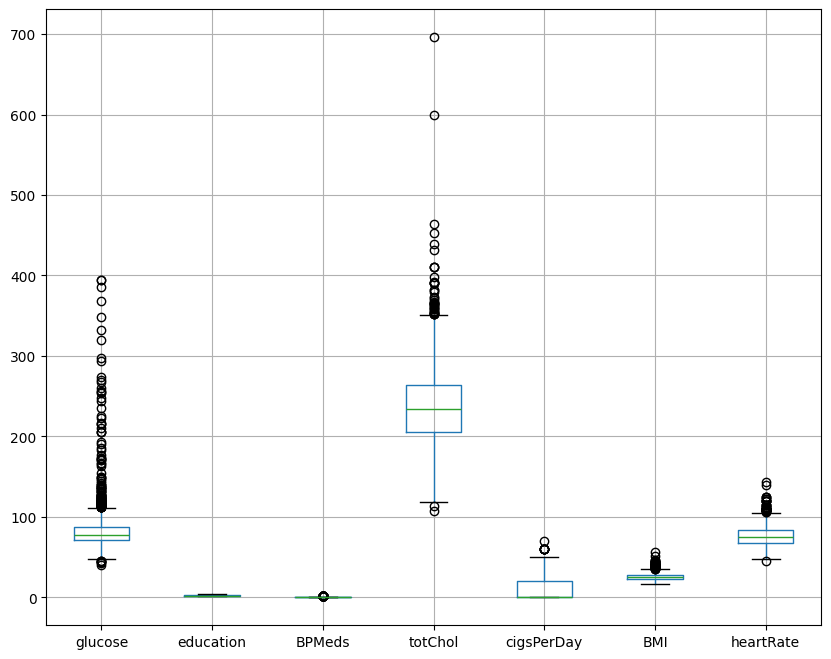

In [47]:
# storing the column that contains null values
null_column_list= ['glucose','education','BPMeds','totChol','cigsPerDay','BMI','heartRate']
# plotting box plot
plt.figure(figsize=(10,8))
df[null_column_list].boxplot()

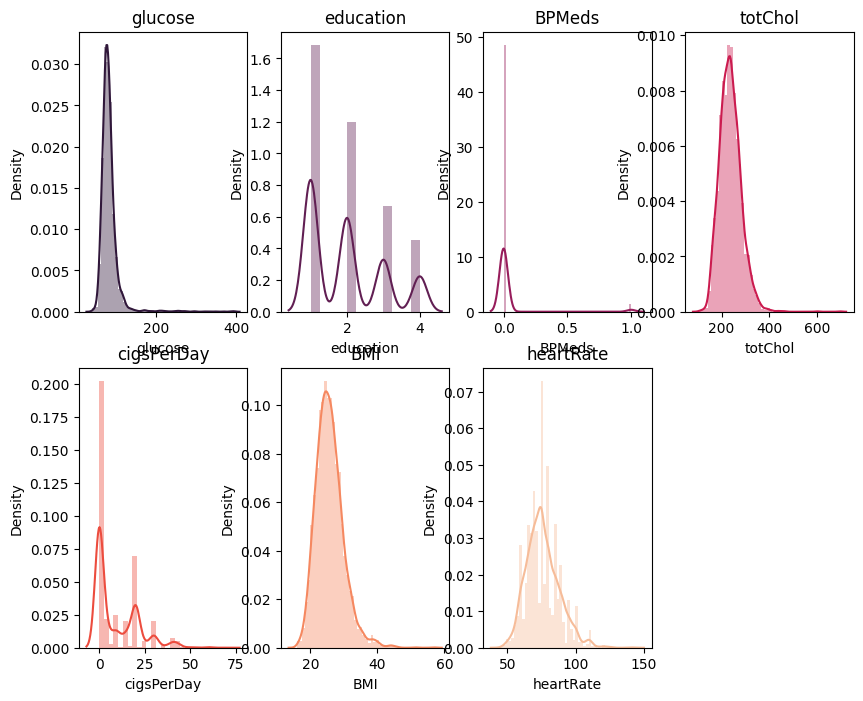

In [48]:
# Iterate over the null column list and plot each column's distribution
colors = sns.color_palette("rocket", len(null_column_list))


fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(10, 8))


axes = axes.flatten()


for i, column in enumerate(null_column_list):
    ax = axes[i]

    sns.distplot(df[column], ax=ax, color=colors[i])
    ax.set_title(column)

for j in range(len(null_column_list), len(axes)):
    axes[j].remove()

plt.show()

* It is a well-known fact that the appropriate measure of central tendency depends on the nature of the data. Typically, the mean is used for data that follows a normal distribution and does not contain any outliers. On the other hand, when dealing with numerical, continuous data that contains extreme values or outliers, the median is the preferred measure of central tendency. For categorical data, the mode is used.

* Based on the outliers and distribution of the data, we have determined that the following measures of central tendency are appropriate for imputing the null values in the following columns.

* "education" , "BPMeds" -> mode: As "education" and "BPMeds" is a categorical variable, the mode is the most appropriate measure of central tendency. The mode represents the most frequently occurring value in the distribution and can provide insight into the most common level of education in the dataset.

* "glucose","totChol", "cigsPerDay", "BMI", "heartRate" -> median: Since this are numerical, continuous variable that contain extreme values or outliers, we have chosen the median as the appropriate measure of central tendency. The median is less sensitive to extreme values than the mean and provides a representative value for the central tendency of the distribution.

In [49]:
# Imputing missing values with median or mode
df.fillna({'glucose': df['glucose'].median(),
           'education': df['education'].mode()[0],
           'BPMeds': df['BPMeds'].mode()[0],
           'totChol': df['totChol'].median(),
           'cigsPerDay': df['cigsPerDay'].median(),
           'BMI': df['BMI'].median(),
           'heartRate': df['heartRate'].median()}, inplace=True)

### What all manipulations have you done and insights you found?

* performed imputation of missing values using a combination of median and mode imputation. Specifically, for the glucose and totChol columns, cigsPerDay, BMI, and heartRate the missing values are replaced with the median of the non-missing values. For the education, BPMeds columns, the missing values are replaced with the mode (most frequently occurring value) of the non-missing values.

* Median and mode imputation are commonly used imputation techniques for handling missing values. Median imputation is often used for continuous variables, as it is less sensitive to outliers compared to mean imputation. Mode imputation is often used for categorical variables or discrete variables with a small number of possible values.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

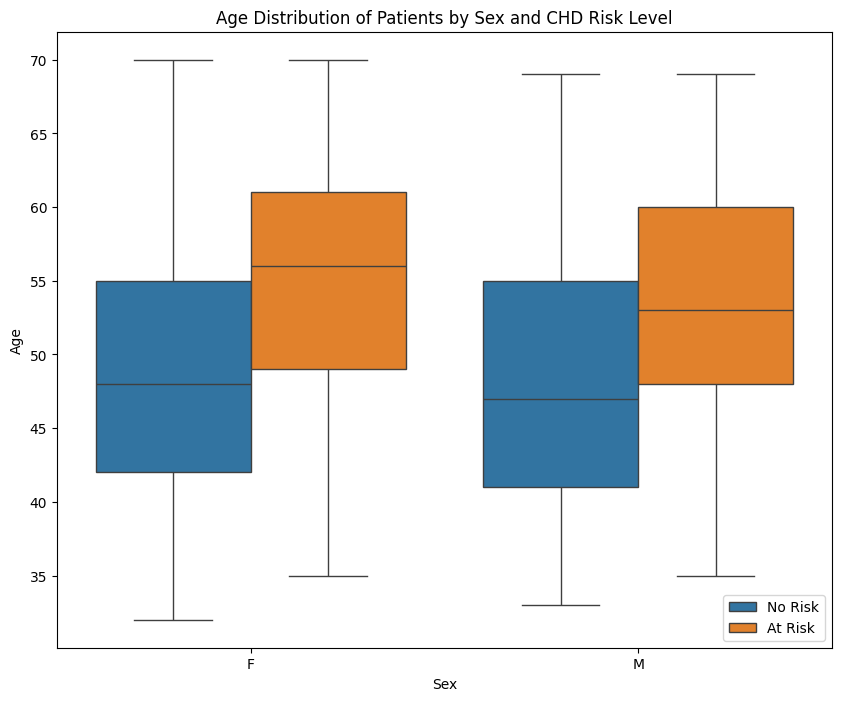

In [50]:
# Chart - 1 visualization code
fig, ax = plt.subplots(figsize=(10,8))
sns.boxplot(x="sex", y="age", hue="TenYearCHD", data= df, ax=ax)
ax.set_title("Age Distribution of Patients by Sex and CHD Risk Level")
ax.set_xlabel("Sex")
ax.set_ylabel("Age")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ["No Risk", "At Risk"], loc="best")
plt.show()

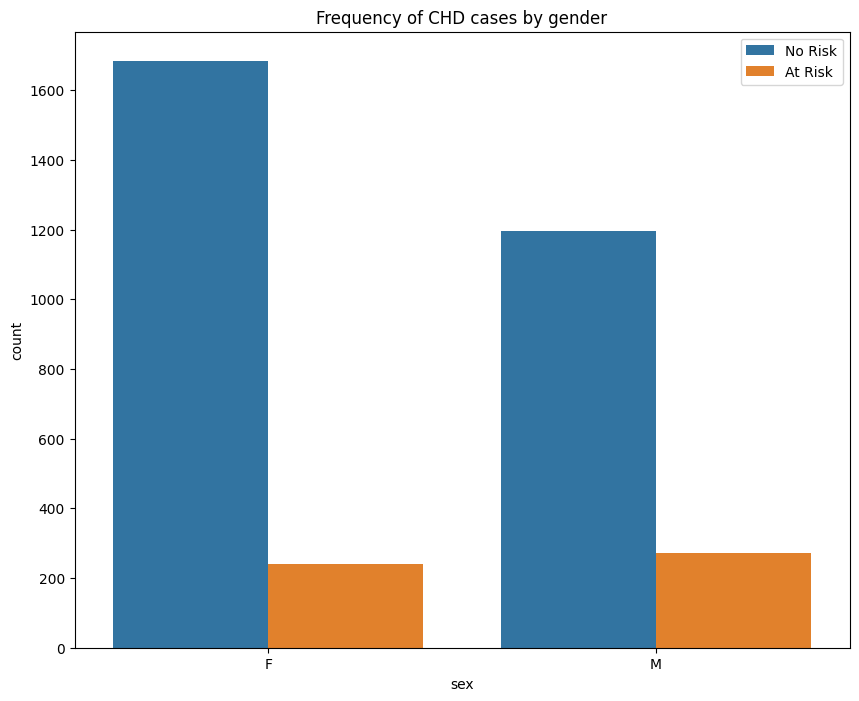

In [51]:
# Chart - 2 visualization code

plt.figure(figsize=(10,8))
sns.countplot(x='sex', hue='TenYearCHD', data= df)
plt.title('Frequency of CHD cases by gender')
plt.legend(['No Risk', 'At Risk'])
plt.show()

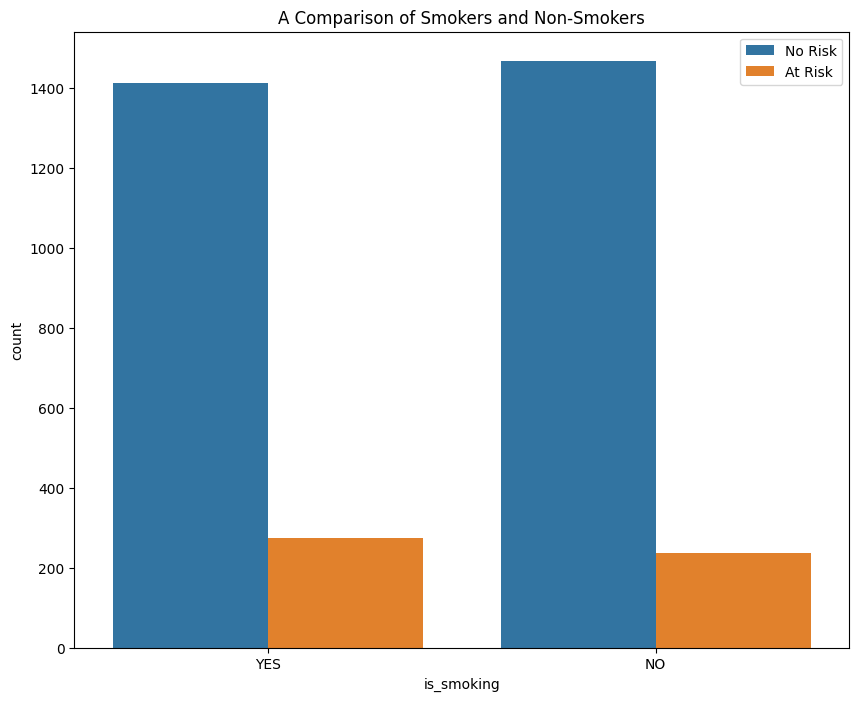

In [52]:
# Chart - 3 visualization code
plt.figure(figsize=(10,8))
sns.countplot(x='is_smoking', hue='TenYearCHD', data= df)
plt.title('A Comparison of Smokers and Non-Smokers')
plt.legend(['No Risk', 'At Risk'])
plt.show()

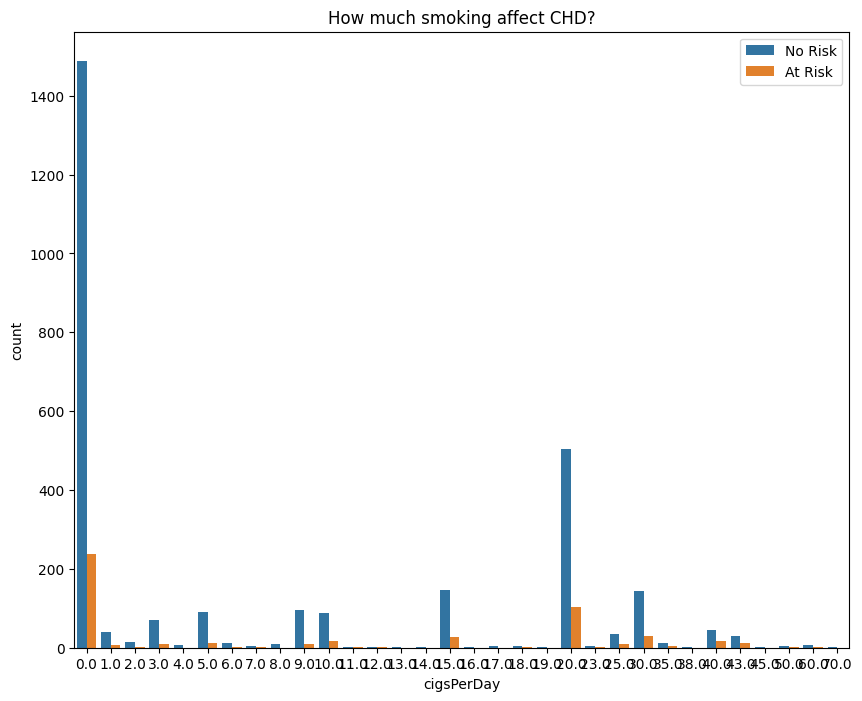

In [53]:
# Chart - 4 visualization code
plt.figure(figsize=(10,8))
sns.countplot(x= df['cigsPerDay'],hue= df['TenYearCHD'])
plt.title('How much smoking affect CHD?')
plt.legend(['No Risk','At Risk'])
plt.show()

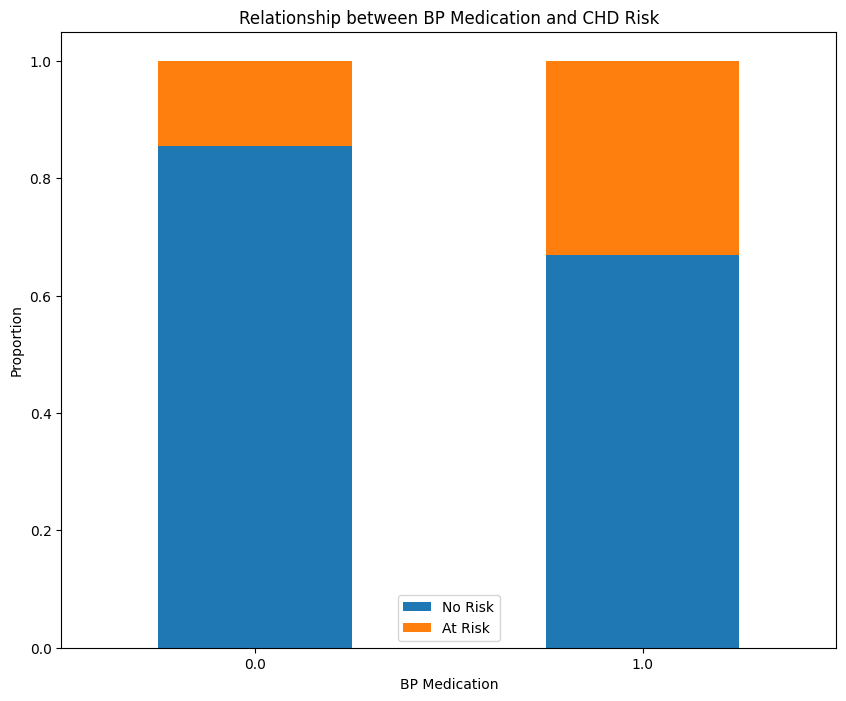

In [54]:
# Chart - 5 visualization code
ct = pd.crosstab(df['BPMeds'], df['TenYearCHD'], normalize='index')
ct.plot(kind='bar', stacked=True, figsize=(10, 8))
plt.title('Relationship between BP Medication and CHD Risk')
plt.xlabel('BP Medication')
plt.xticks(rotation=0)
plt.ylabel('Proportion')
plt.legend(['No Risk', 'At Risk'])
plt.show()

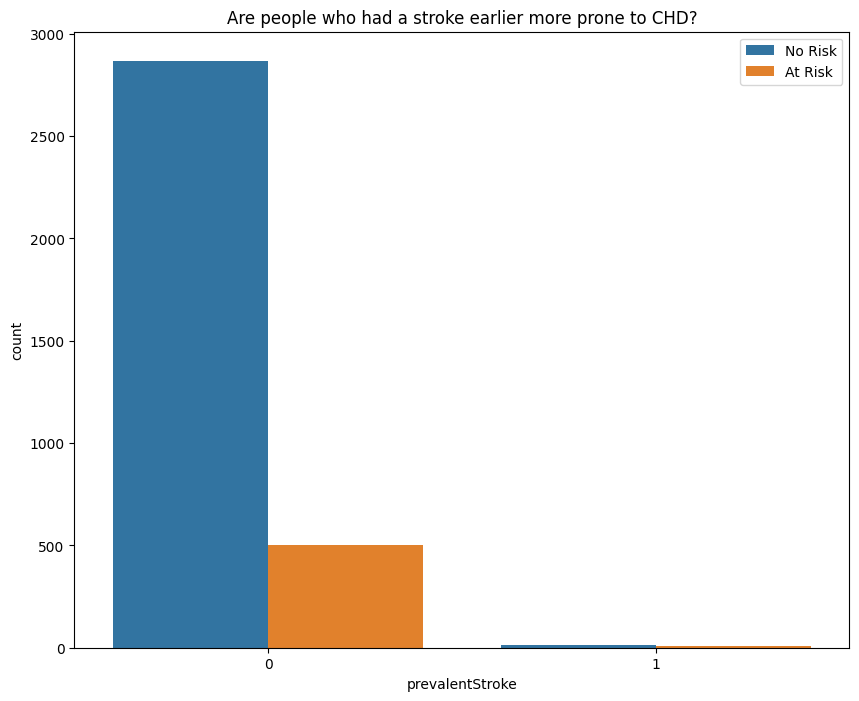

In [55]:
# Chart - 6 visualization code
plt.figure(figsize=(10,8))
sns.countplot(x=df['prevalentStroke'], hue=df['TenYearCHD'])
plt.title('Are people who had a stroke earlier more prone to CHD?')
plt.legend(['No Risk', 'At Risk'], loc='best')
plt.show()


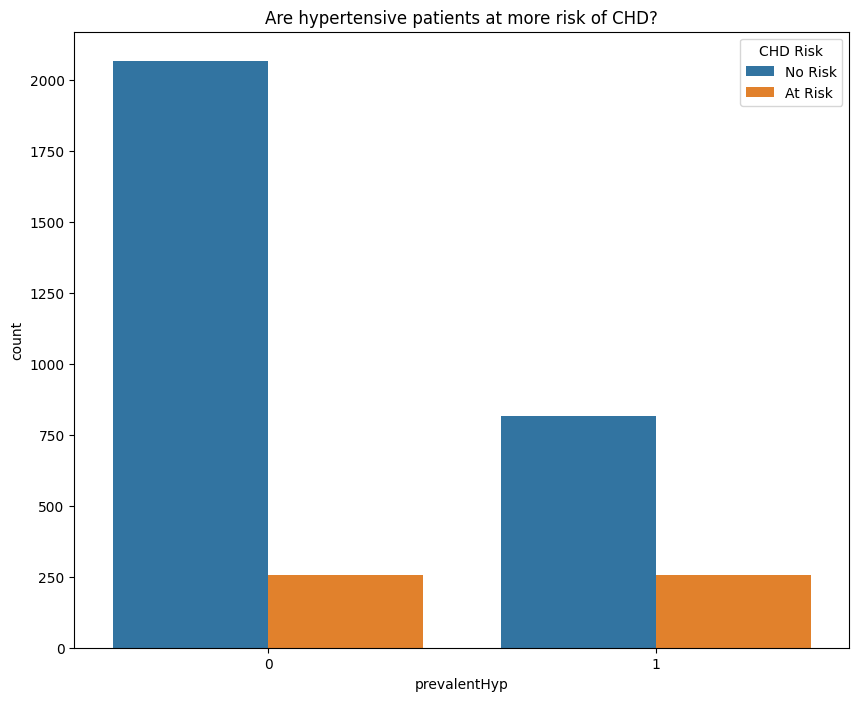

In [56]:
# Chart - 7 visualization code
plt.figure(figsize=(10,8))
sns.countplot(x=df['prevalentHyp'], hue=df['TenYearCHD'])
plt.title('Are hypertensive patients at more risk of CHD?')
plt.legend(title='CHD Risk', labels=['No Risk', 'At Risk'])
plt.show()

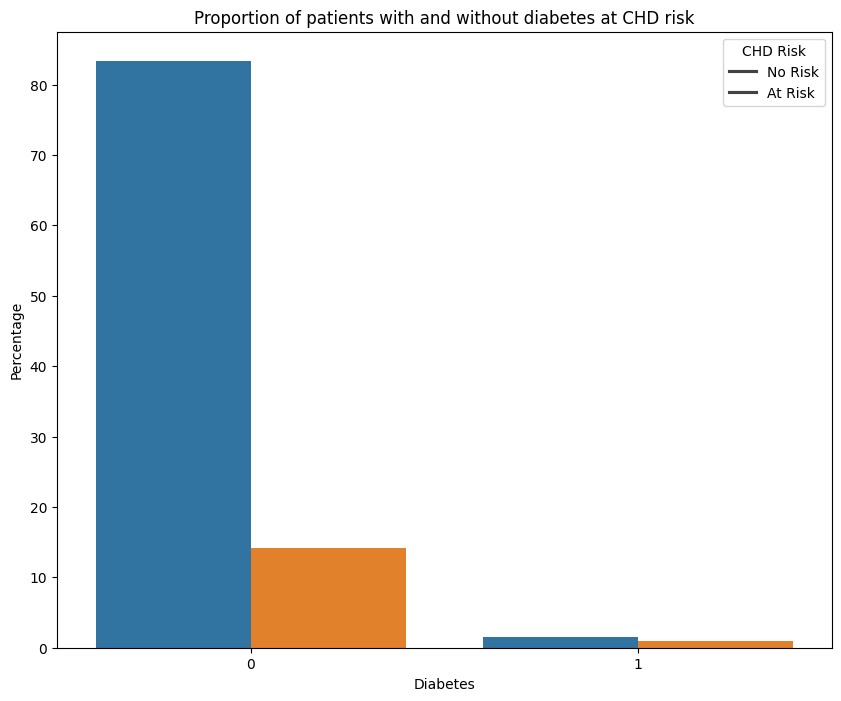

In [57]:
# Chart - 8 visualization code
plt.figure(figsize=(10,8))
sns.barplot(x=df['diabetes'], y=df['TenYearCHD'], hue=df['TenYearCHD'], estimator=lambda x: len(x) / len(df) * 100)
plt.title('Proportion of patients with and without diabetes at CHD risk')
plt.xlabel('Diabetes')
plt.ylabel('Percentage')
plt.legend(title='CHD Risk', labels=['No Risk', 'At Risk'])
plt.show()

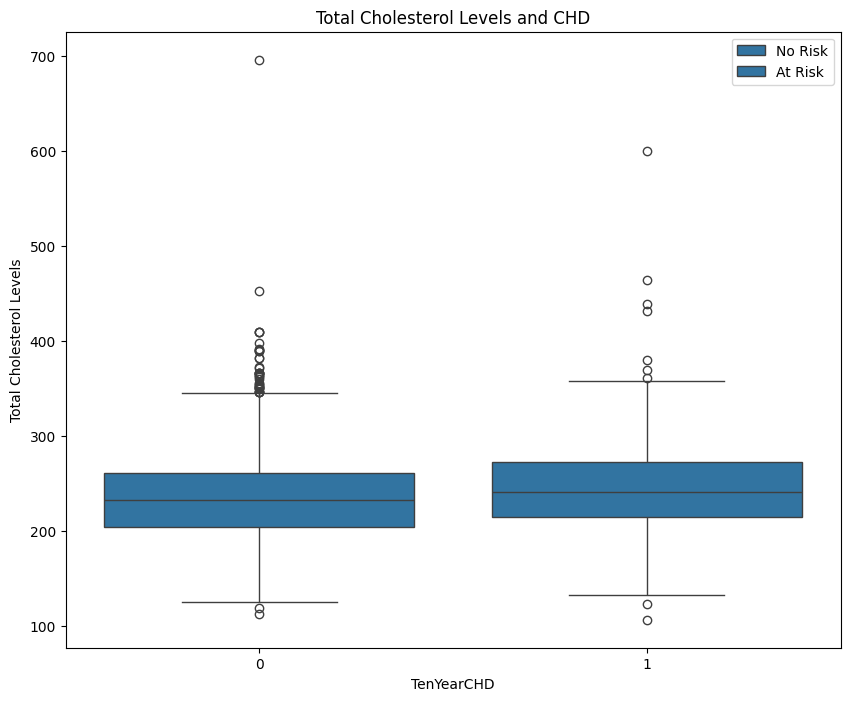

In [58]:
# Chart - 9 visualization code
plt.figure(figsize=(10,8))
sns.boxplot(x='TenYearCHD', y='totChol', data=df)
plt.title('Total Cholesterol Levels and CHD')
plt.xlabel('TenYearCHD')
plt.ylabel('Total Cholesterol Levels')
plt.legend(['No Risk', 'At Risk'])
plt.show()


<Figure size 1500x1000 with 0 Axes>

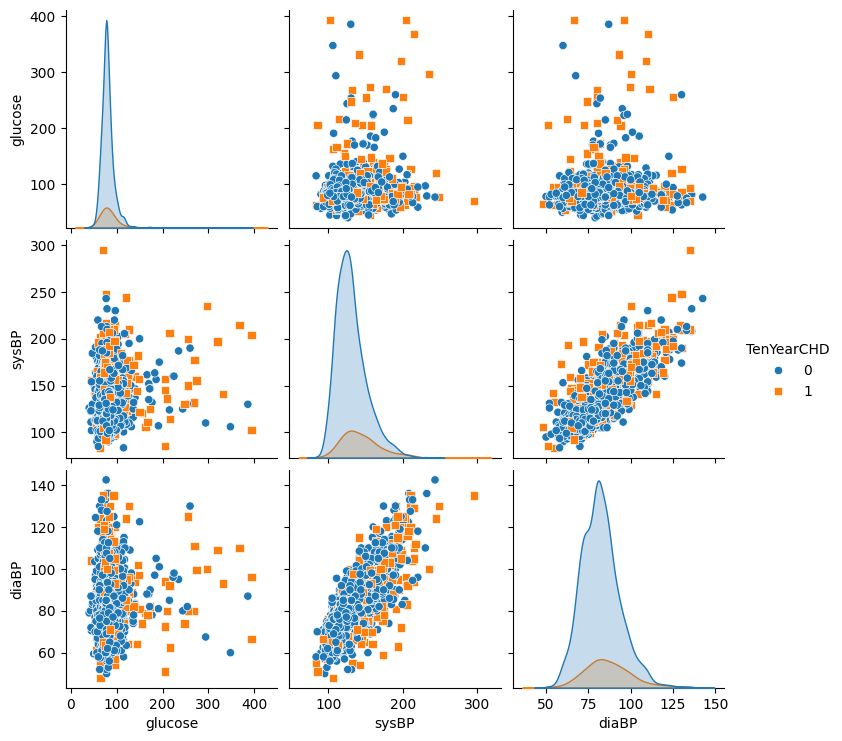

In [59]:
# Chart - 10 visualization code
cols = ['glucose', 'sysBP', 'diaBP', 'TenYearCHD']

# create the scatter plot matrix
plt.figure(figsize=(15,10))
sns.pairplot(df[cols], hue='TenYearCHD', markers=['o', 's'])
plt.show()

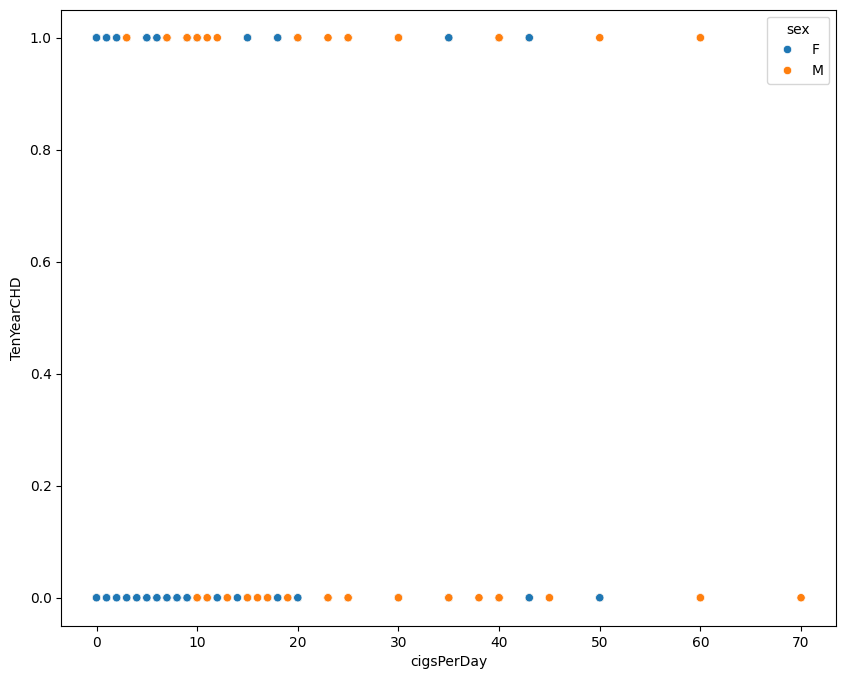

In [60]:
# Chart - 11 visualization code
plt.figure(figsize=(10,8))
cols = ['sex', 'cigsPerDay', 'TenYearCHD']
sns.scatterplot(x='cigsPerDay', y='TenYearCHD', hue='sex', data=df)
plt.show()

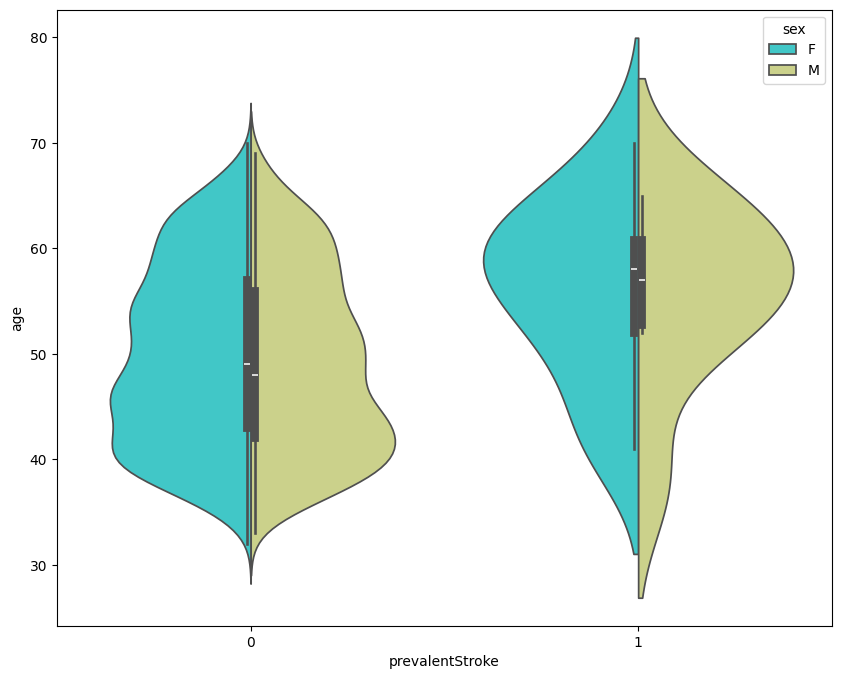

In [61]:
# Chart - 12 visualization code
plt.figure(figsize=(10,8))
sns.violinplot(x='prevalentStroke',y="age",data=df, hue='sex', split='True', palette='rainbow')
plt.show()

* it is made clear that most of the prevalent strokes were shown by patients abbove age 45 and most of those patients are females.

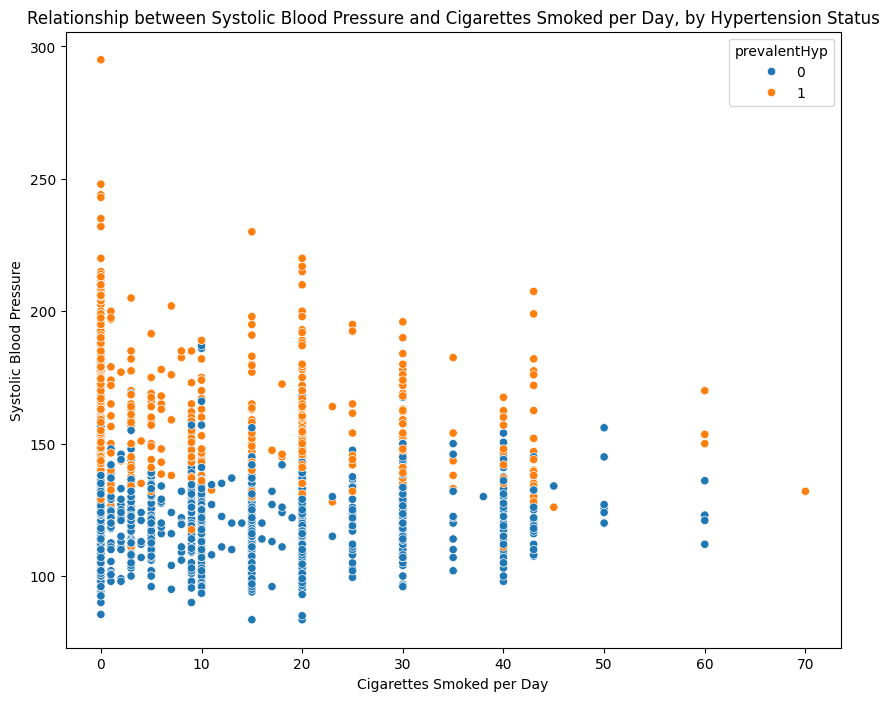

In [62]:
# Chart - 13 visualization code
plt.figure(figsize=(10,8))
sns.scatterplot(x='cigsPerDay', y='sysBP', hue='prevalentHyp', data=df)
plt.title('Relationship between Systolic Blood Pressure and Cigarettes Smoked per Day, by Hypertension Status')
plt.xlabel('Cigarettes Smoked per Day')
plt.ylabel('Systolic Blood Pressure')
plt.show()

<Axes: >

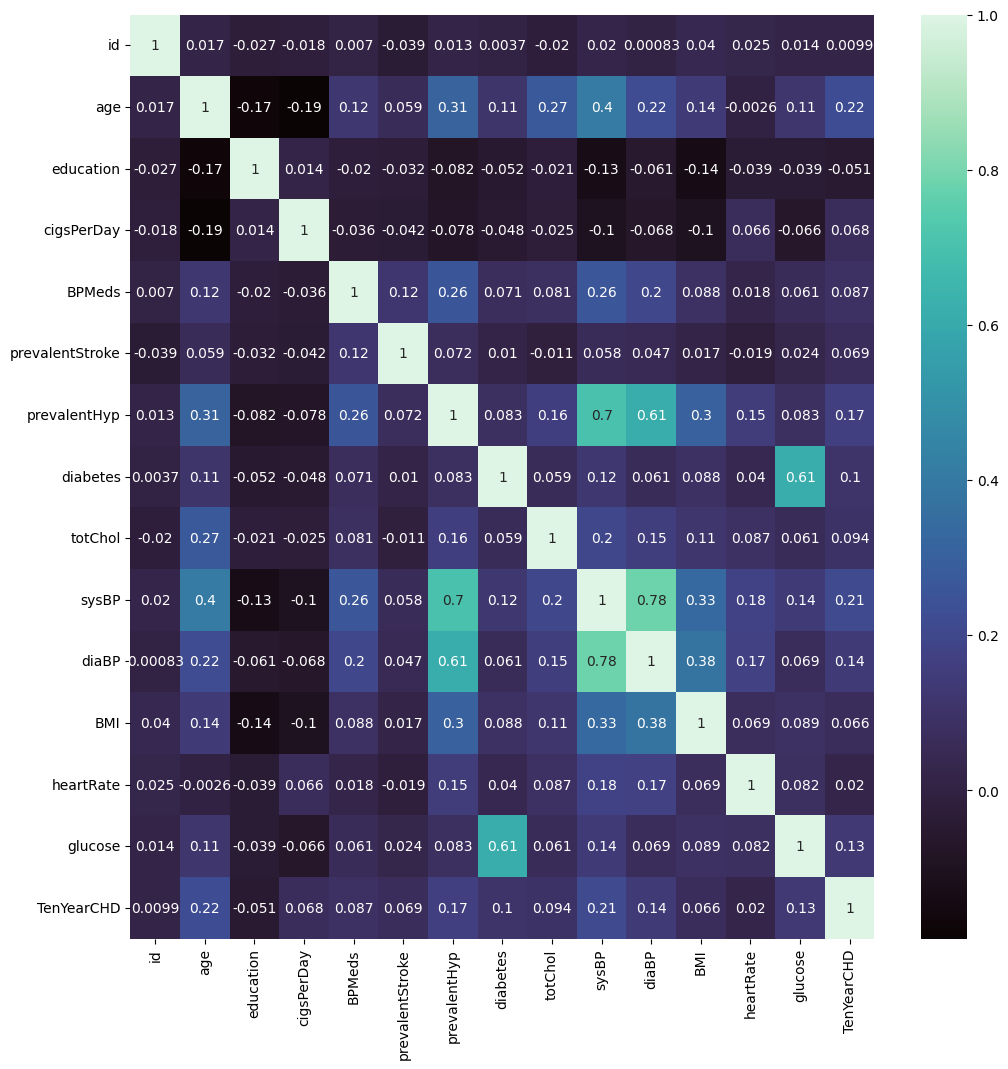

In [63]:
# Correlation Heatmap visualization code
plt.figure(figsize=(12,12))
correlation = df.corr(numeric_only=True)
sns.heatmap((correlation), annot=True, cmap=sns.color_palette("mako", as_cmap=True))

**The Correlation Heatmap shows the pairwise correlation between all numerical features in the dataset.**

* From corelation chart we can see that age is highly correlated with TenYearCHD by 22%. This suggests that these features may be important predictors of CHD risk.

* From the heatmap, we can see that age, systolic blood pressure, and diastolic blood pressure have a relatively strong correlation with the TenYearCHD target variable.

* Additionally, we can see that there is a moderate positive correlation between systolic and diastolic blood pressure, by 78%.

* As well as diabetes and glucose are correlated by 61%.

* Also prevalent hypertension highly correlated with systolic blood pressure, and diastolic blood pressure by 70% and 61% respectively.

* And age is negatively correlated with education and cigarettes per day with 17% and 19% respectively.

<Figure size 1500x1000 with 0 Axes>

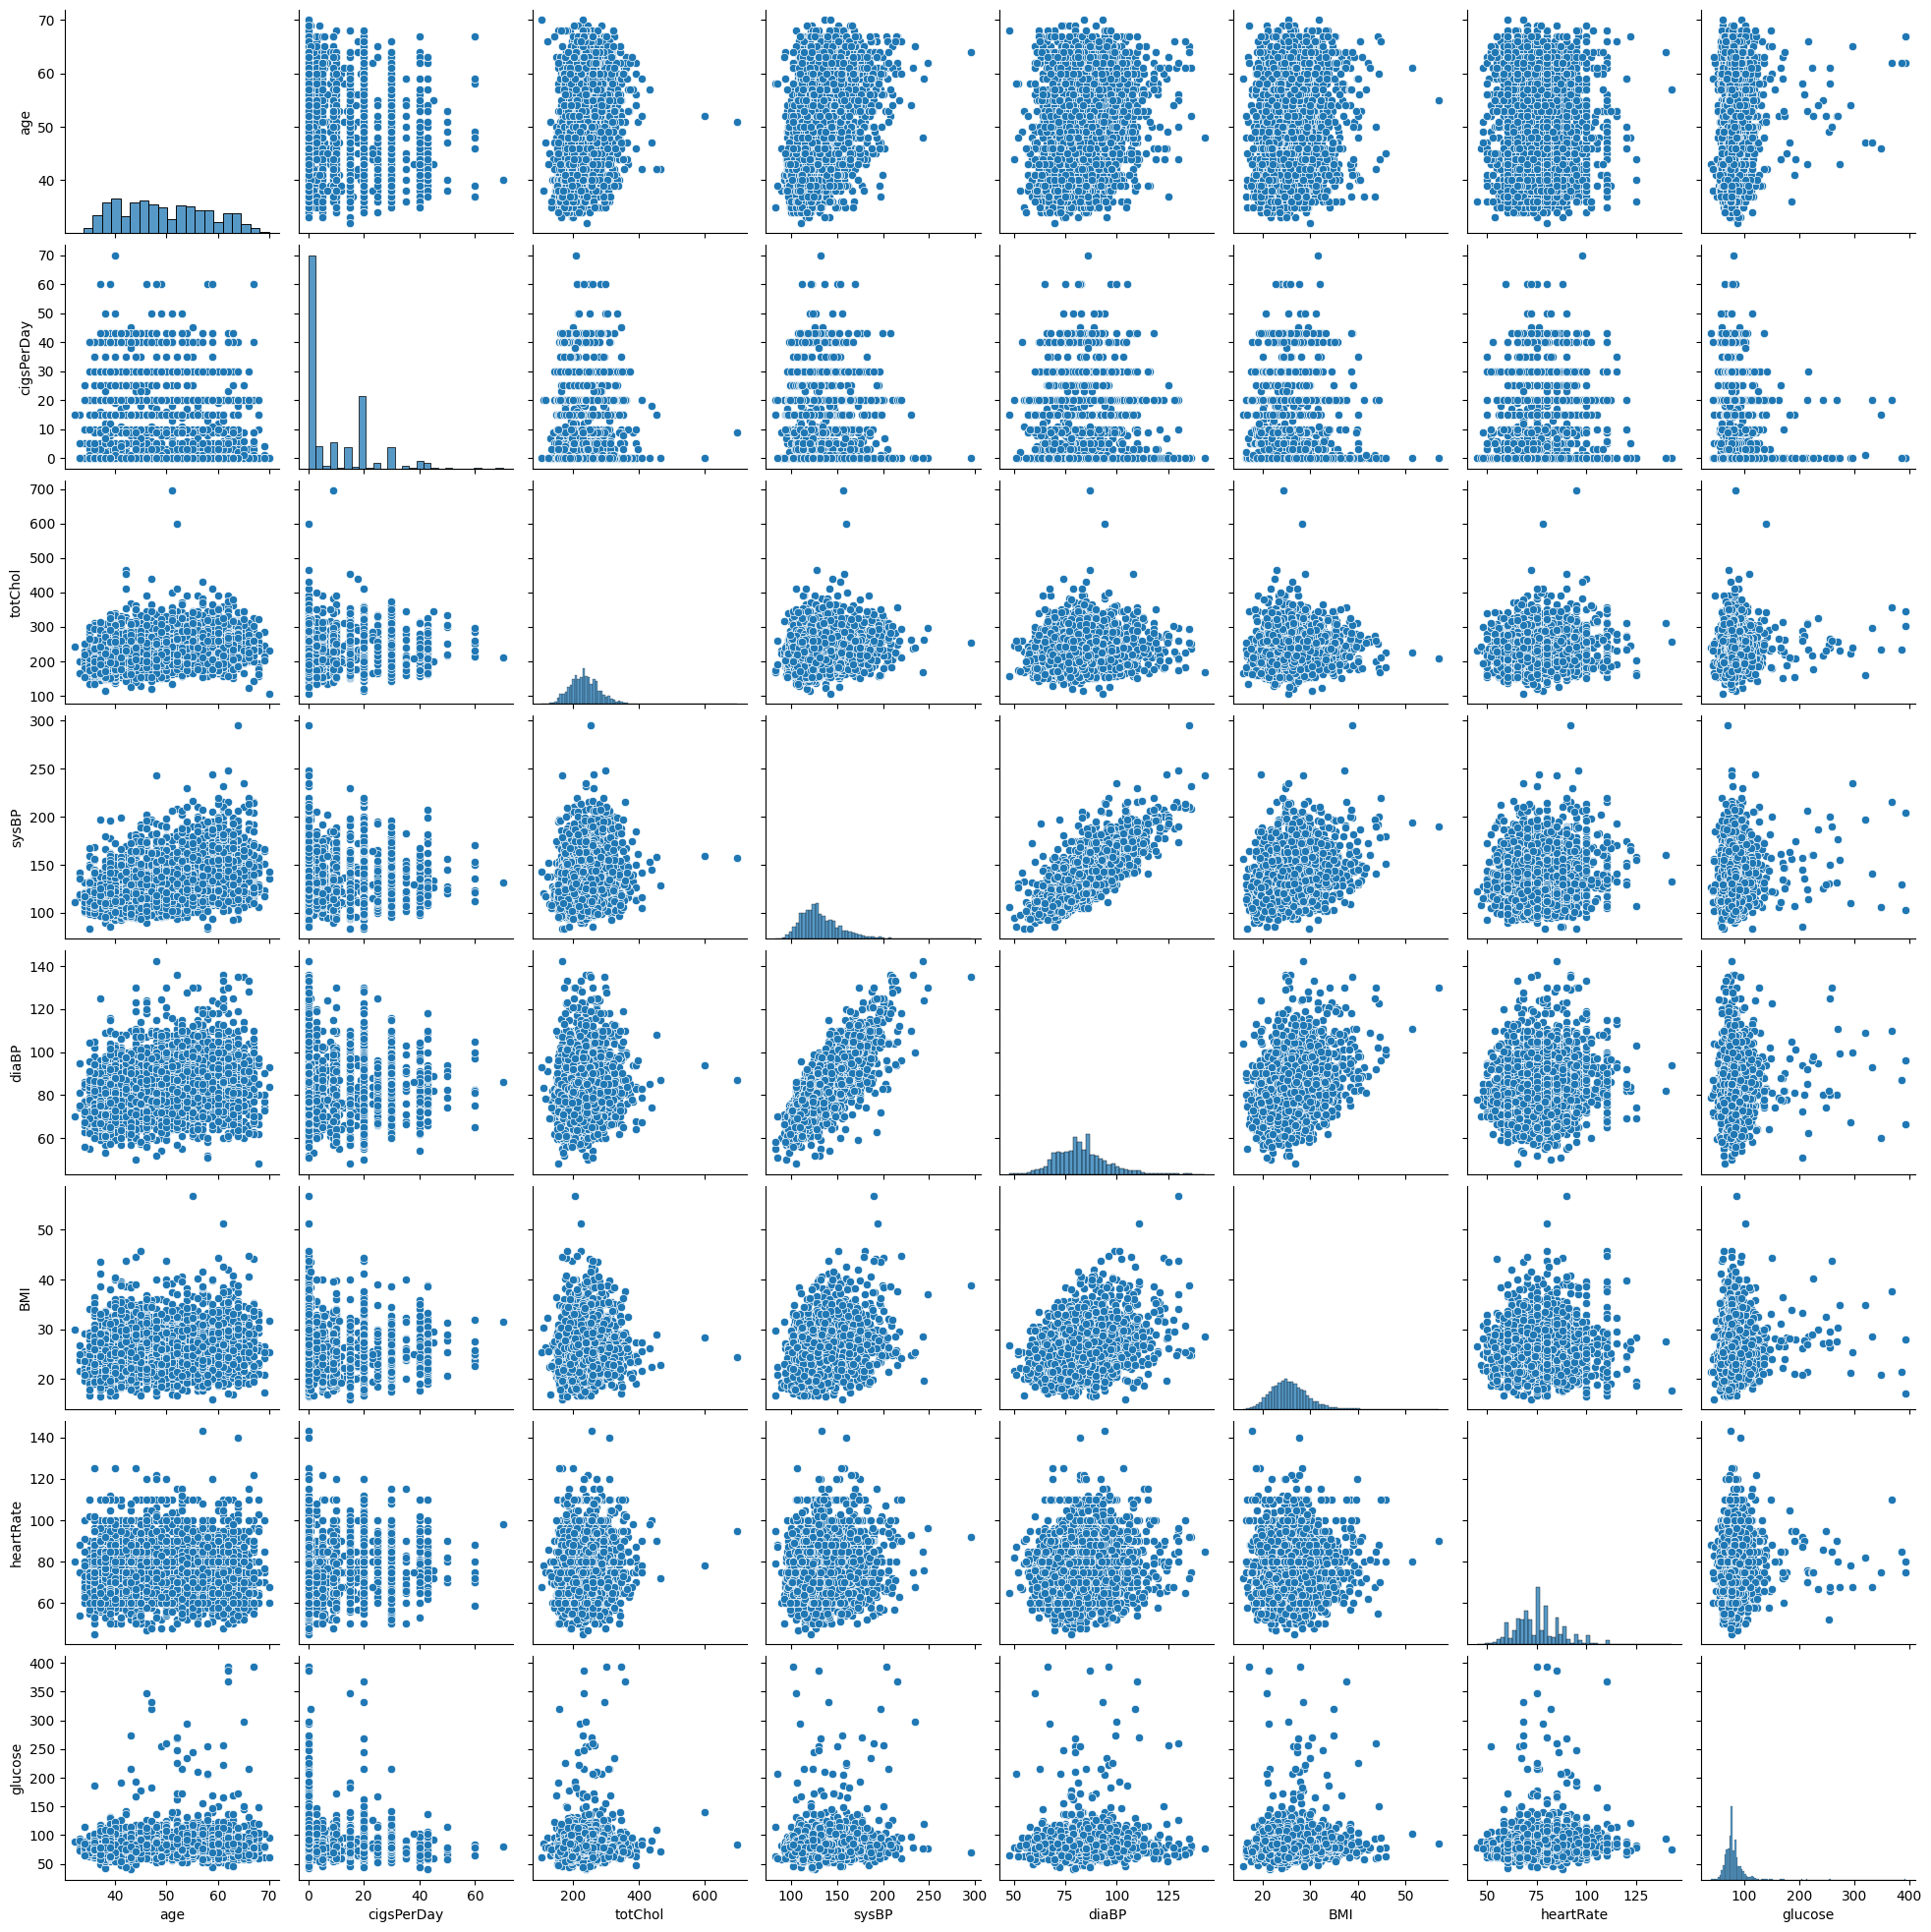

In [64]:
# Pair Plot visualization code
plt.figure(figsize=(15,10))
sns.pairplot(df[continous_variable])
plt.show()

## ***5. Hypothesis Testing***

### **Hypothetical Statement - 1) Higher total cholesterol levels are associated with an increased risk of CHD**

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* Null Hypothesis - There is no difference in the mean total cholesterol levels between the two groups

* Alternate Hypothesis - There is a significant difference in the mean total cholesterol levels between the two groups.

#### 2. Perform an appropriate statistical test.

In [65]:
# Perform Statistical Test to obtain P-Value
import scipy.stats as stats

# Separate the dataset into two groups based on CHD status
chd = df[df['TenYearCHD'] == 1] # Patients with CHD
no_chd = df[df['TenYearCHD'] == 0] # Patients without CHD

# Perform a two-sample t-test to compare the mean total cholesterol levels of the two groups
t_stat, p_val = stats.ttest_ind(chd['totChol'], no_chd['totChol'], equal_var=False)

# Print the calculated t-statistic and p-value
print('t_stat=%.3f, p_val=%.3f' % (t_stat, p_val))

# Determine if the null hypothesis should be rejected based on the p-value
if p_val < 0.05:
    print('Reject the null hypothesis')
else:
    print('Fail to reject the null hypothesis')

# Print the p-value
print('p-value:', p_val)

t_stat=5.065, p_val=0.000
Reject the null hypothesis
p-value: 5.310852329016036e-07


### **Hypothetical Statement - 2) Diabetic patients are at a higher risk of developing CHD than non-diabetic patients**

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* Null hypothesis: There is no significant difference in the risk of developing CHD between diabetic and non-diabetic patients.

* Alternative hypothesis: Diabetic patients are at a higher risk of developing CHD than non-diabetic patients.

#### 2. Perform an appropriate statistical test.

In [66]:
# Perform Statistical Test to obtain P-Value
diabetic = df[df['diabetes'] == 1]
non_diabetic = df[df['diabetes'] == 0]

# Perform a two-sample t-test to compare the mean TenYearCHD rates of the two groups
t_stat, p_val = stats.ttest_ind(diabetic['TenYearCHD'], non_diabetic['TenYearCHD'], equal_var=False)

print('t_stat=%.3f, p_val=%.3f' % (t_stat, p_val))
if p_val > 0.05:
    print('Accept Null Hypothesis')
else:
    print('Reject Null Hypothesis')

# Print the p-value
print('p-value:', p_val)

t_stat=4.453, p_val=0.000
Reject Null Hypothesis
p-value: 2.463686008547406e-05


* The t-statistic is a measure of the difference in means between diabetic and non-diabetic patients, normalized by the standard error of the difference. The p-value is a measure of the probability of observing such a difference in means by chance alone, assuming that the null hypothesis is true.

* The obtained p-value of 0.000 is less than the significance level of 0.05, which suggests that the probability of observing such a difference in means by chance alone is very low. Therefore, we reject the null hypothesis and conclude that diabetic patients are at a higher risk of developing CHD than non-diabetic patients.

##### Which statistical test have you done to obtain P-Value?

* The two-sample t-test was used to obtain the p-value for the hypothesis "Diabetic patients are at a higher risk of developing CHD than non-diabetic patients."

### **Hypothetical Statement - 3) Individuals above the age of 50 are more likely to be at risk of TenYearCHD.**

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* Null hypothesis - Age has no effect on the risk of TenYearCHD.

* Alternative hypothesis - Patients over 50 years of age have a higher risk of TenYearCHD than those who are under 50 years of age.

#### 2. Perform an appropriate statistical test.

In [67]:
# Perform Statistical Test to obtain P-Value
import statsmodels.stats.proportion as smp

above_50 = df[df['age'] > 50]
below_50 = df[df['age'] <= 50]

# Calculate the proportion of patients with TenYearCHD in each group
prop_above_50 = above_50['TenYearCHD'].mean()
prop_below_50 = below_50['TenYearCHD'].mean()

# Perform a one-tailed z-test to compare the proportions of the two groups
z_score, p_val = smp.proportions_ztest([prop_above_50 * len(above_50), prop_below_50 * len(below_50)], [len(above_50), len(below_50)], alternative='larger')

print('z_score=%.3f, p_val=%.3f' % (z_score, p_val))

if p_val < 0.05:
    print('Reject Null Hypothesis')
else:
    print('Accept Null Hypothesis')

# Print the p-value
print('p-value:', p_val)

z_score=11.155, p_val=0.000
Reject Null Hypothesis
p-value: 3.388983060064358e-29


* The results of the test indicate that the probability of observing a difference in the proportion of TenYearCHD risk between patients above 50 years of age and those below 50 years of age due to chance is very low.

* Rejected the null hypothesis and conclude that patients who are above 50 years of age are at a significantly higher risk of TenYearCHD than those who are below 50 years of age.

##### Which statistical test have you done to obtain P-Value?

* I used a one-tailed Z-test to compare the proportions of patients with TenYearCHD above and below 50 years of age.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [68]:
# Handling Missing Values & Missing Value Imputation
df.isnull().sum()

,0
id,0
age,0
education,0
sex,0
is_smoking,0
cigsPerDay,0
BPMeds,0
prevalentStroke,0
prevalentHyp,0
diabetes,0


#### What all missing value imputation techniques have you used and why did you use those techniques?

* There are no remaining null values in our dataset as we have already processed and handled them in data wrangling.

### 2. Handling Outliers

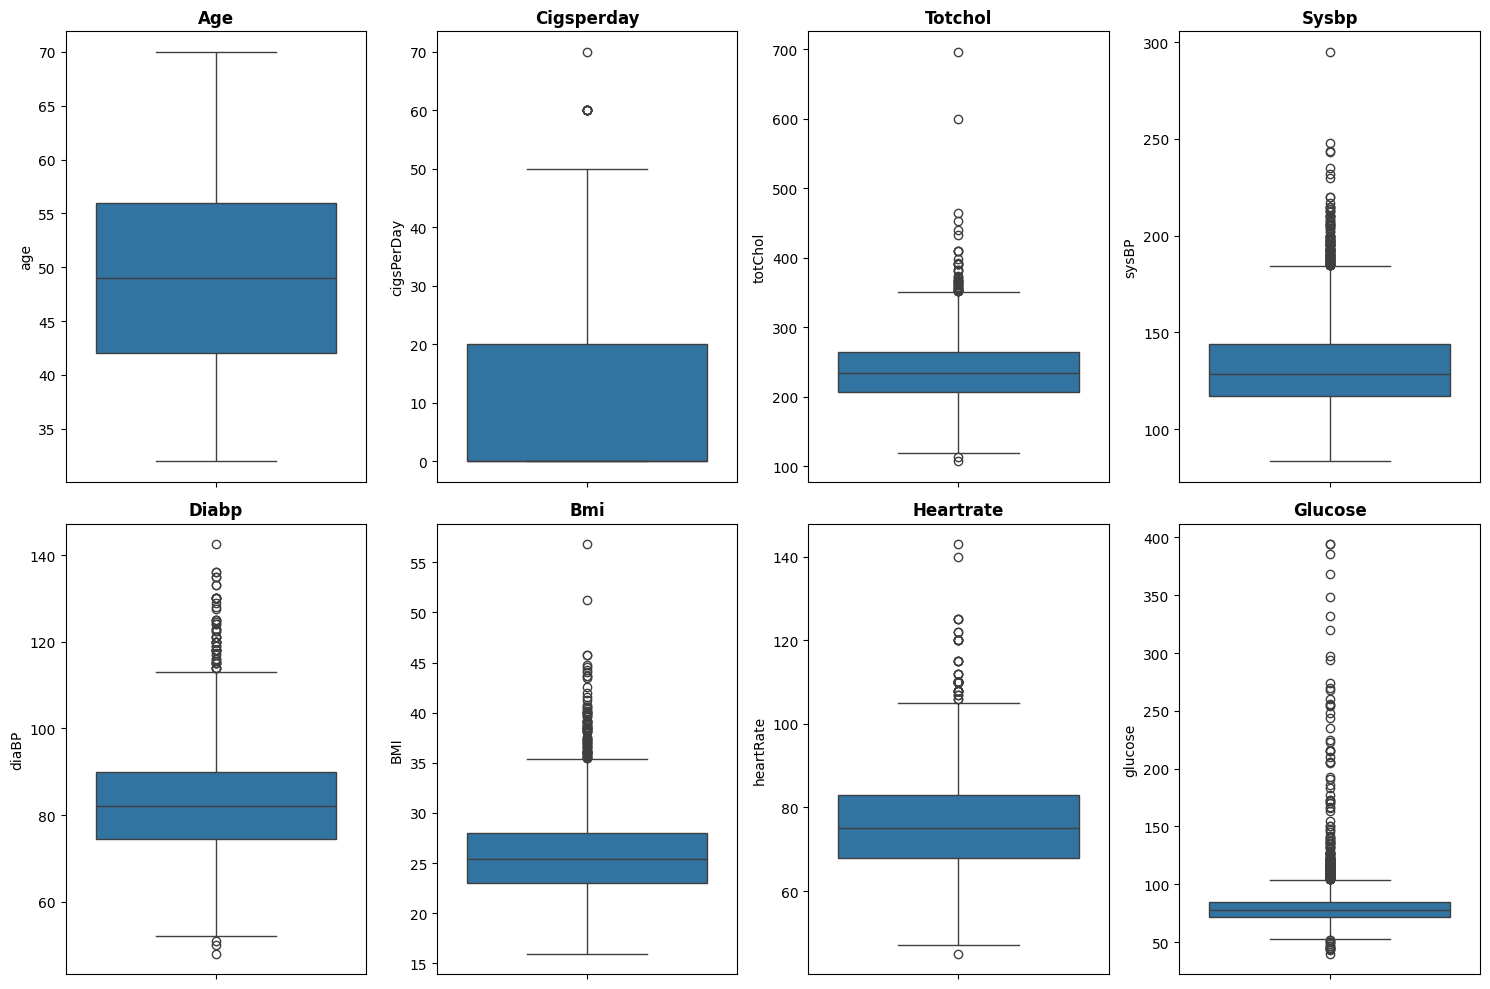

In [69]:
# Handling Outliers & Outlier treatments
fig, axes = plt.subplots(2, 4, figsize=(15, 10))
axes = axes.flatten()
for ax, col in zip(axes, continous_variable):
    sns.boxplot(df[col], ax=ax)
    ax.set_title(col.title(), weight='bold')
plt.tight_layout()

In [70]:
df[continous_variable] = np.log(df[continous_variable] +1 )

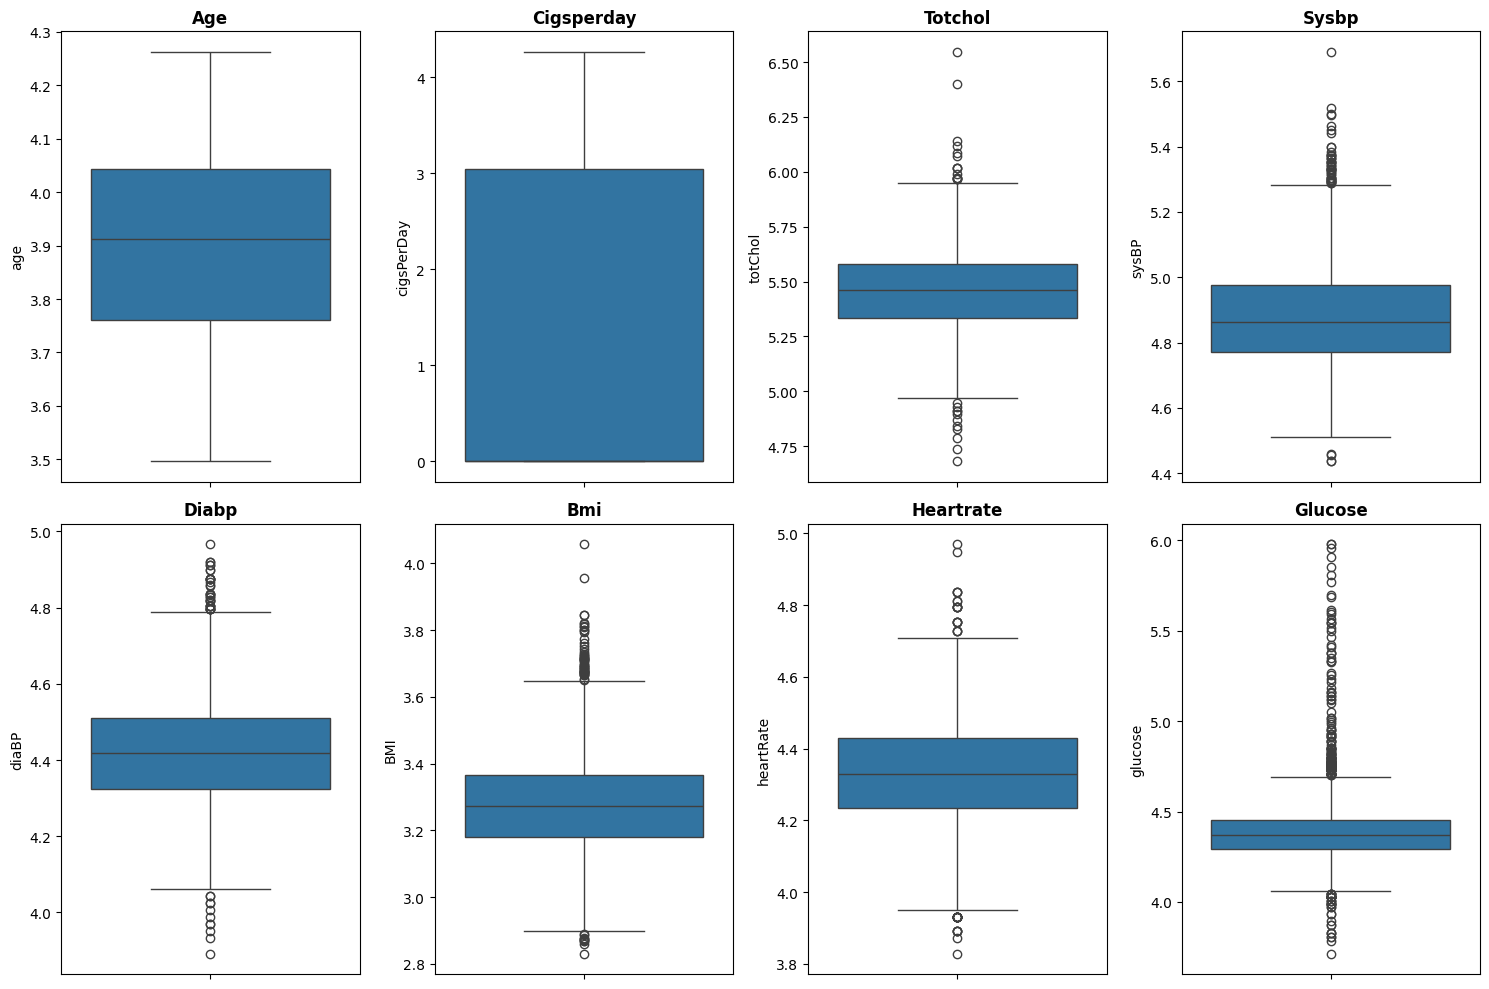

In [71]:
fig, axes = plt.subplots(2, 4, figsize=(15, 10))
axes = axes.flatten()
for ax, col in zip(axes, continous_variable):
    sns.boxplot(df[col], ax=ax)
    ax.set_title(col.title(), weight='bold')
plt.tight_layout()

##### What all outlier treatment techniques have you used and why did you use those techniques?

* I used LOG TRANSFORMATION method to remove outlier from the dataset.

* I used this method because it is a statistical model and easy to implement yet it shows effective results.

* This transformaton can also help to normalize the distribution of the data and make it more symmetrical.

### 3. Categorical Encoding

In [72]:
df.head()

,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,0,4.174387,2.0,F,YES,1.386294,0.0,0,0,0,5.402677,5.003946,4.454347,3.272606,4.510860,4.394449,1
1,1,3.610918,4.0,M,NO,0.000000,0.0,0,1,0,5.361292,5.129899,4.595120,3.426540,4.290459,4.330733,0
2,2,3.850148,1.0,F,YES,2.397895,0.0,0,0,0,5.525453,4.762174,4.276666,3.061052,4.488636,4.553877,0
3,3,3.931826,1.0,M,YES,3.044522,0.0,0,1,0,5.455321,5.068904,4.488636,3.376221,4.234107,4.553877,1
4,4,4.174387,1.0,F,YES,3.433987,0.0,0,0,0,5.488938,4.923624,4.454347,3.311273,4.262680,4.356709,0


In [73]:
# Encode your categorical columns
df['sex'] = pd.get_dummies(df['sex'], drop_first=True)
df['is_smoking'] = pd.get_dummies(df['is_smoking'], drop_first=True)

In [74]:
df.head()

,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,0,4.174387,2.0,False,True,1.386294,0.0,0,0,0,5.402677,5.003946,4.454347,3.272606,4.510860,4.394449,1
1,1,3.610918,4.0,True,False,0.000000,0.0,0,1,0,5.361292,5.129899,4.595120,3.426540,4.290459,4.330733,0
2,2,3.850148,1.0,False,True,2.397895,0.0,0,0,0,5.525453,4.762174,4.276666,3.061052,4.488636,4.553877,0
3,3,3.931826,1.0,True,True,3.044522,0.0,0,1,0,5.455321,5.068904,4.488636,3.376221,4.234107,4.553877,1
4,4,4.174387,1.0,False,True,3.433987,0.0,0,0,0,5.488938,4.923624,4.454347,3.311273,4.262680,4.356709,0


In [75]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3390 entries, 0 to 3389
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               3390 non-null   int64  
 1   age              3390 non-null   float64
 2   education        3390 non-null   float64
 3   sex              3390 non-null   bool   
 4   is_smoking       3390 non-null   bool   
 5   cigsPerDay       3390 non-null   float64
 6   BPMeds           3390 non-null   float64
 7   prevalentStroke  3390 non-null   int64  
 8   prevalentHyp     3390 non-null   int64  
 9   diabetes         3390 non-null   int64  
 10  totChol          3390 non-null   float64
 11  sysBP            3390 non-null   float64
 12  diaBP            3390 non-null   float64
 13  BMI              3390 non-null   float64
 14  heartRate        3390 non-null   float64
 15  glucose          3390 non-null   float64
 16  TenYearCHD       3390 non-null   int64  
dtypes: bool(2), fl

#### What all categorical encoding techniques have you used & why did you use those techniques?

* The reason for using this technique is that categorical variables are usually non-numeric, but machine learning algorithms require input to be in a numerical format. So we are using one-hot encoding to transform the categorical variables 'sex' and 'is_smoking' into numerical variables in the form of binary values (0 or 1).

* Specifically, it is using the get_dummies() function from the pandas library to create dummy variables, which will represent the categories of each variable as a separate binary column.

* Additionally, the use of drop_first=True parameter is to avoid multicollinearity in the dataset which may occur when two dummy variables are highly correlated.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [76]:
# Manipulate Features to minimize feature correlation and create new features
df.head()

,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,0,4.174387,2.0,False,True,1.386294,0.0,0,0,0,5.402677,5.003946,4.454347,3.272606,4.510860,4.394449,1
1,1,3.610918,4.0,True,False,0.000000,0.0,0,1,0,5.361292,5.129899,4.595120,3.426540,4.290459,4.330733,0
2,2,3.850148,1.0,False,True,2.397895,0.0,0,0,0,5.525453,4.762174,4.276666,3.061052,4.488636,4.553877,0
3,3,3.931826,1.0,True,True,3.044522,0.0,0,1,0,5.455321,5.068904,4.488636,3.376221,4.234107,4.553877,1
4,4,4.174387,1.0,False,True,3.433987,0.0,0,0,0,5.488938,4.923624,4.454347,3.311273,4.262680,4.356709,0


* Upon further investigation of heart issues, it was found that pulse pressure, which is the difference between systolic and diastolic blood pressure, has a notable impact on CHD. Hence, we can create a new feature called PP (pulse pressure) which will combine the systolic and diastolic blood pressure readings into a single column.

In [77]:
df['pulsePressure'] = df['sysBP'] - df['diaBP']

In [78]:
df.head()

,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD,pulsePressure
0,0,4.174387,2.0,False,True,1.386294,0.0,0,0,0,5.402677,5.003946,4.454347,3.272606,4.510860,4.394449,1,0.549599
1,1,3.610918,4.0,True,False,0.000000,0.0,0,1,0,5.361292,5.129899,4.595120,3.426540,4.290459,4.330733,0,0.534779
2,2,3.850148,1.0,False,True,2.397895,0.0,0,0,0,5.525453,4.762174,4.276666,3.061052,4.488636,4.553877,0,0.485508
3,3,3.931826,1.0,True,True,3.044522,0.0,0,1,0,5.455321,5.068904,4.488636,3.376221,4.234107,4.553877,1,0.580268
4,4,4.174387,1.0,False,True,3.433987,0.0,0,0,0,5.488938,4.923624,4.454347,3.311273,4.262680,4.356709,0,0.469277


#### 2. Feature Selection

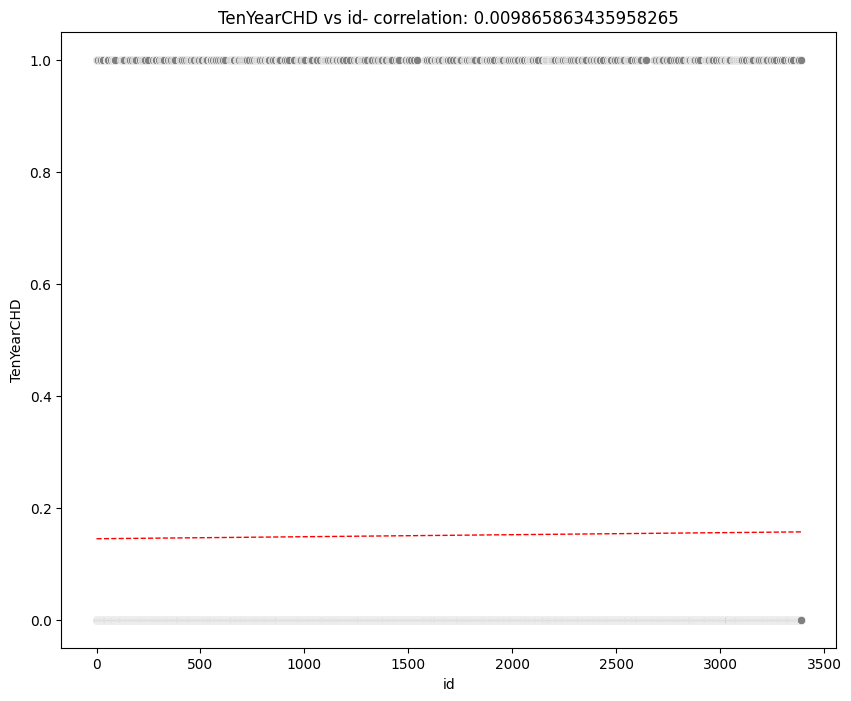

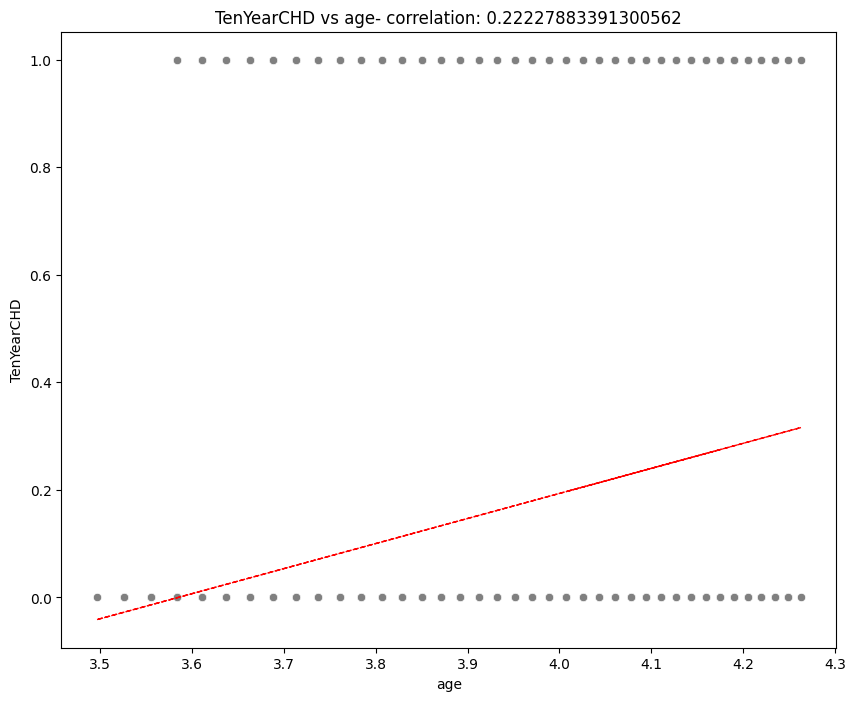

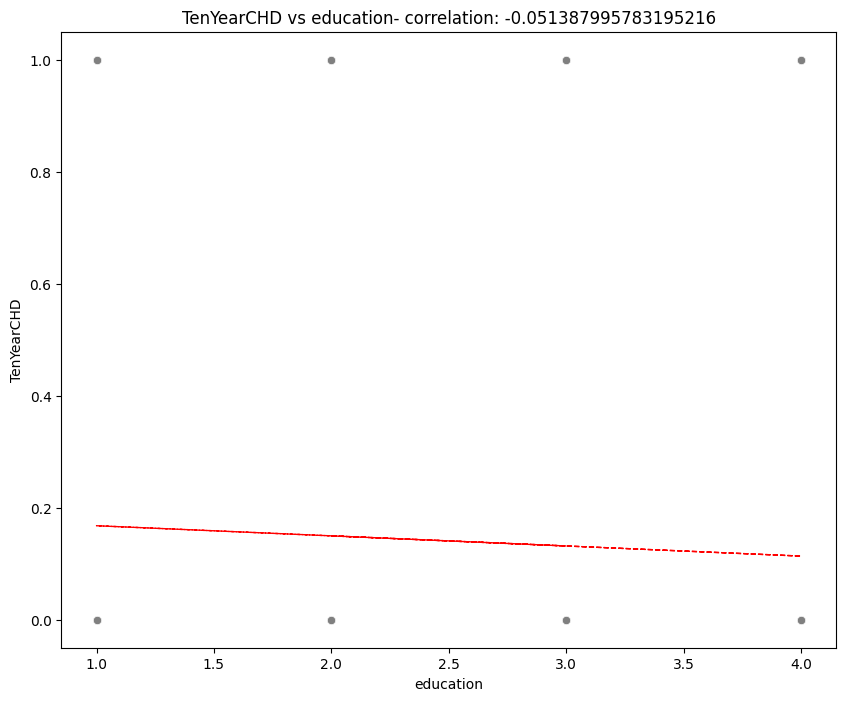

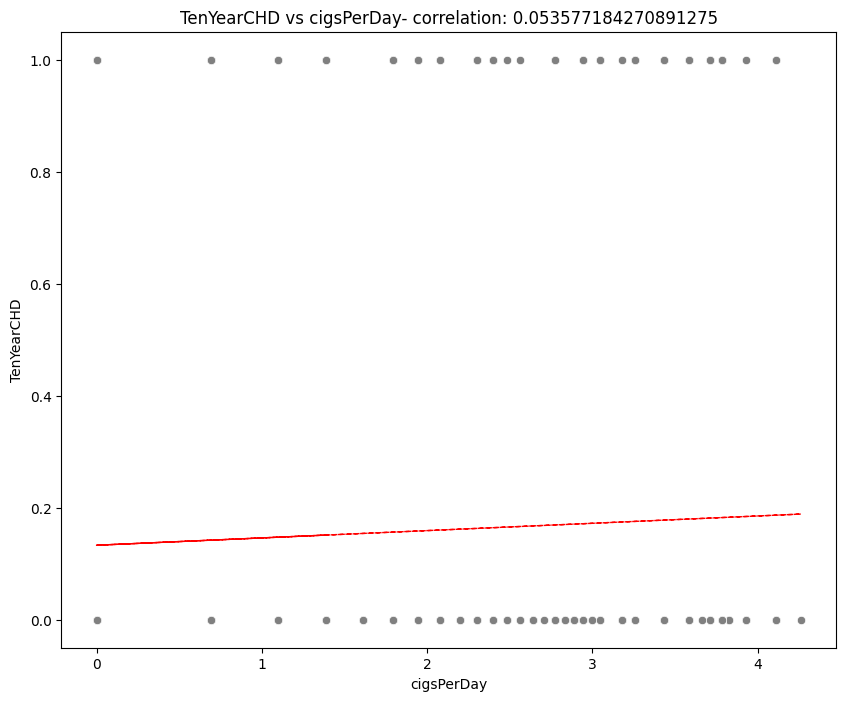

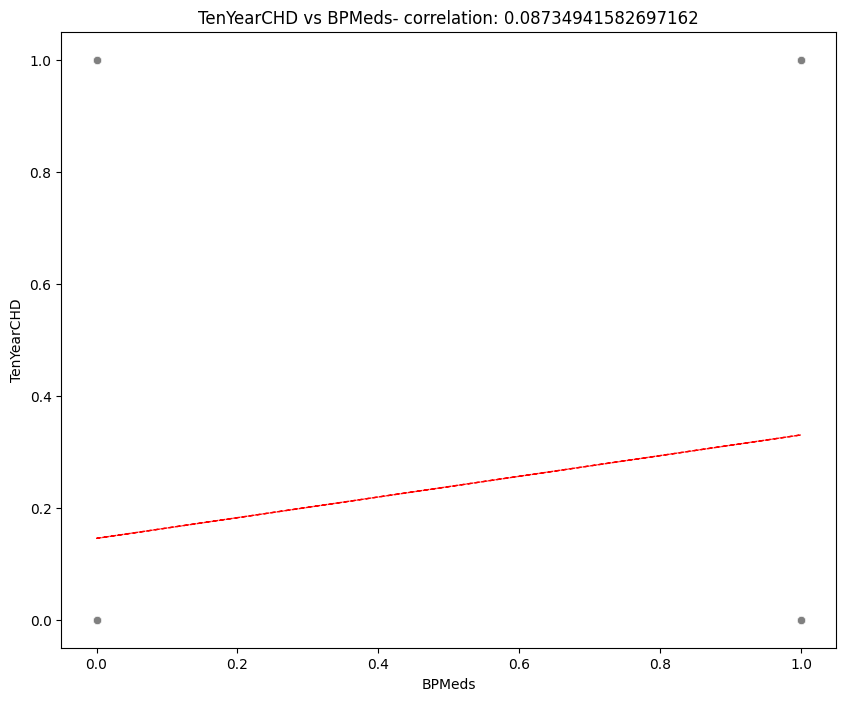

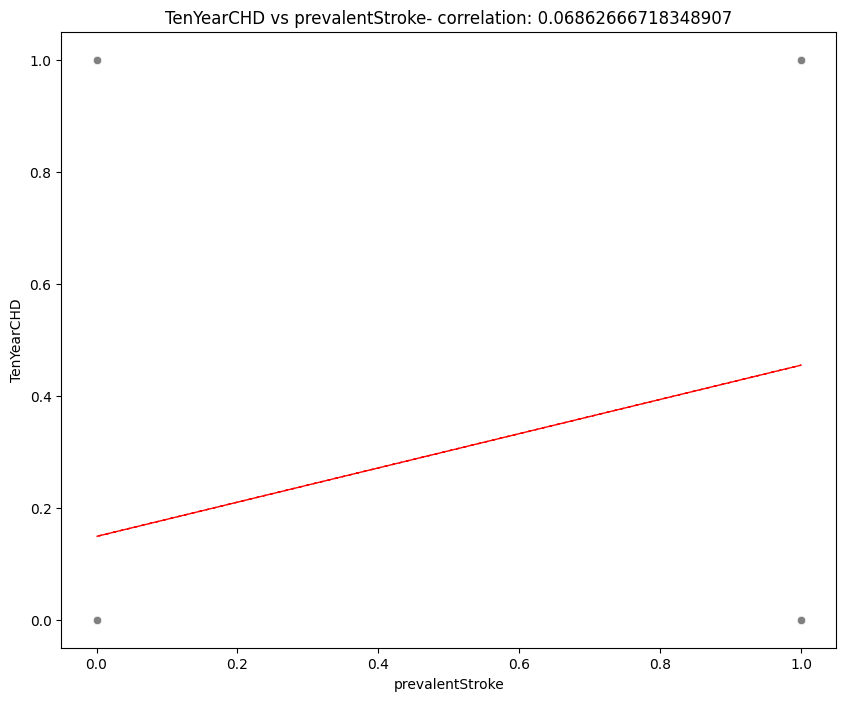

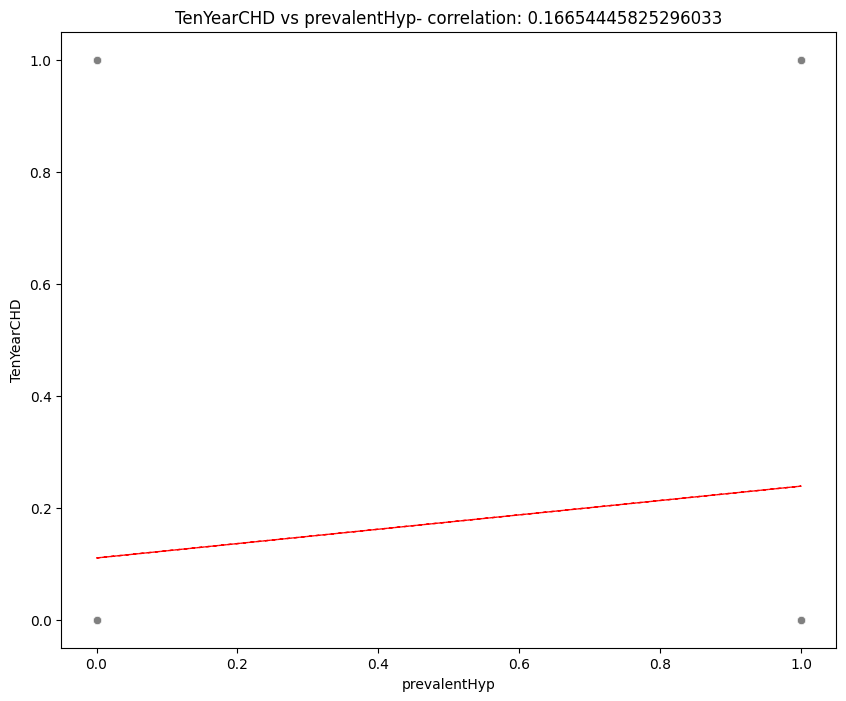

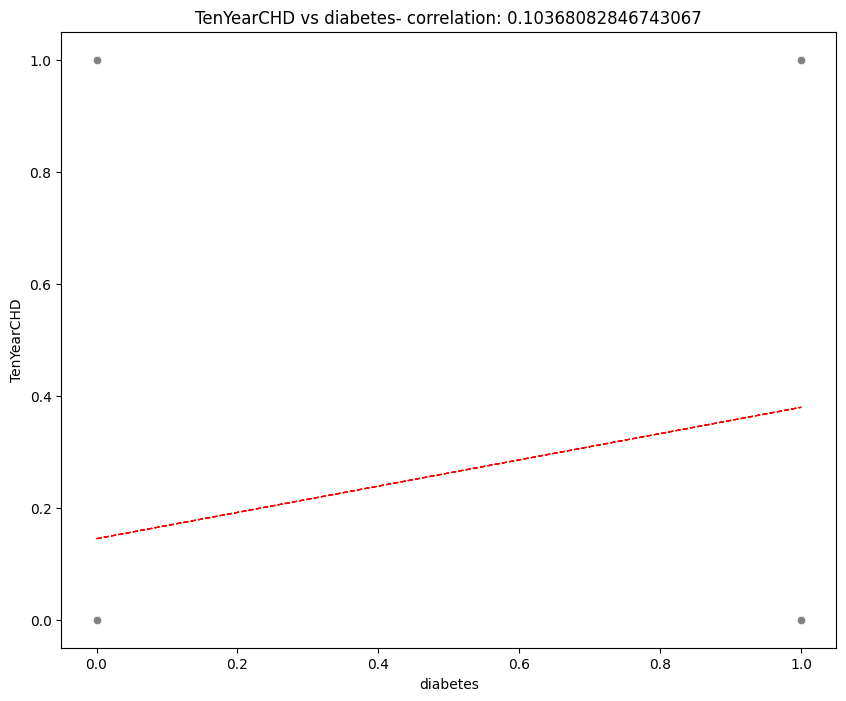

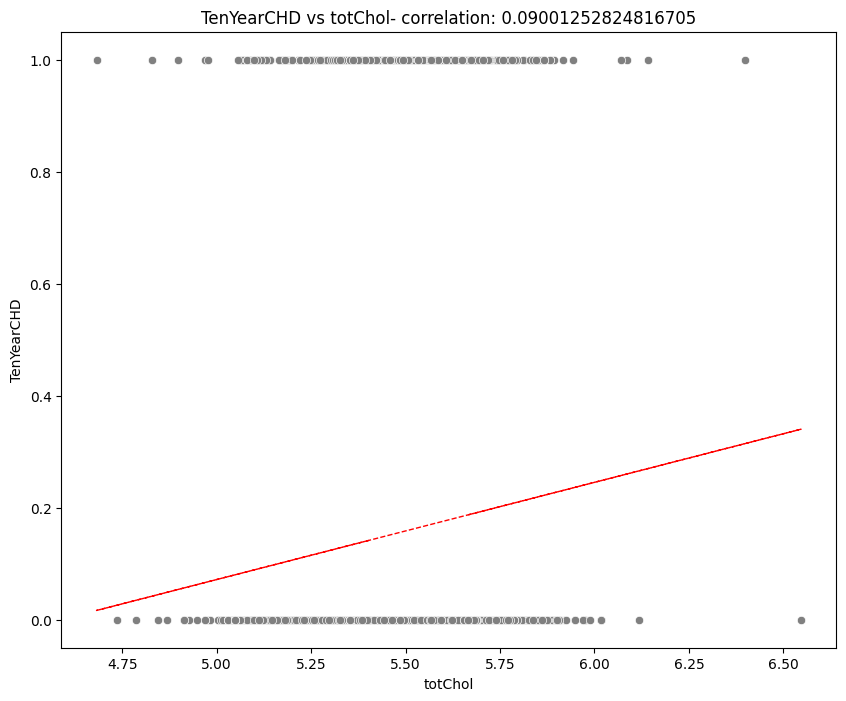

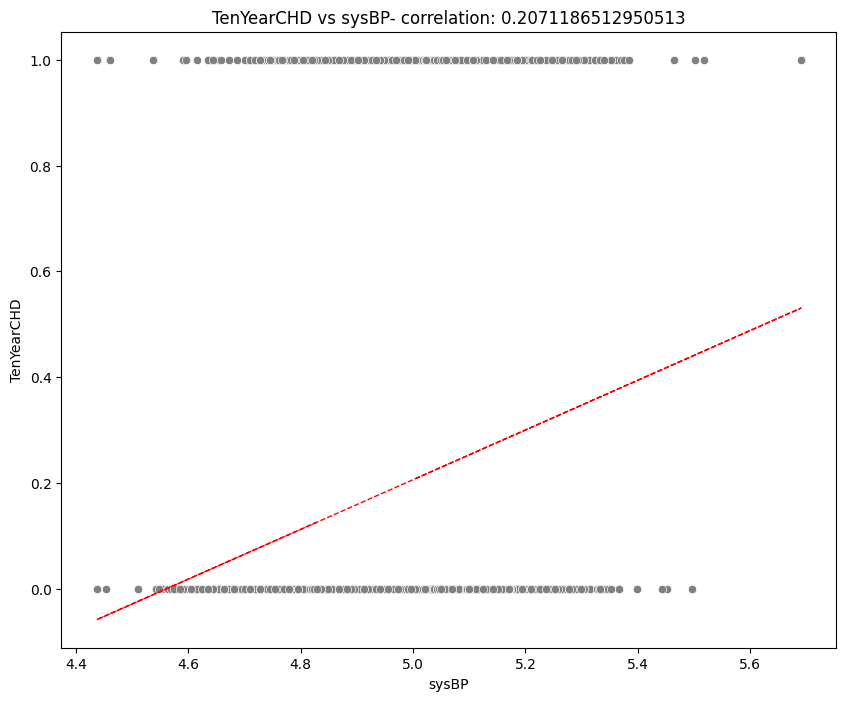

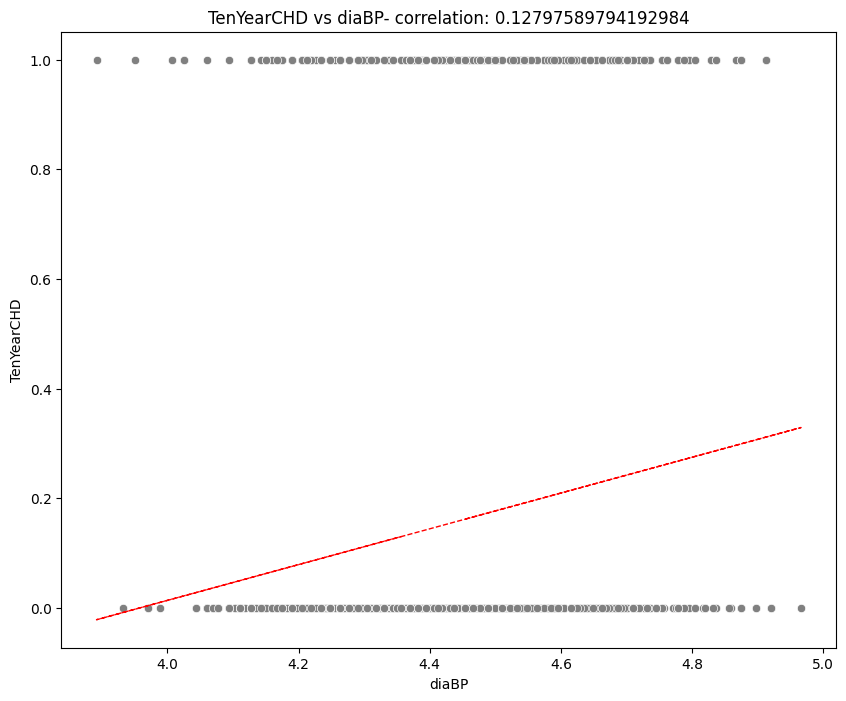

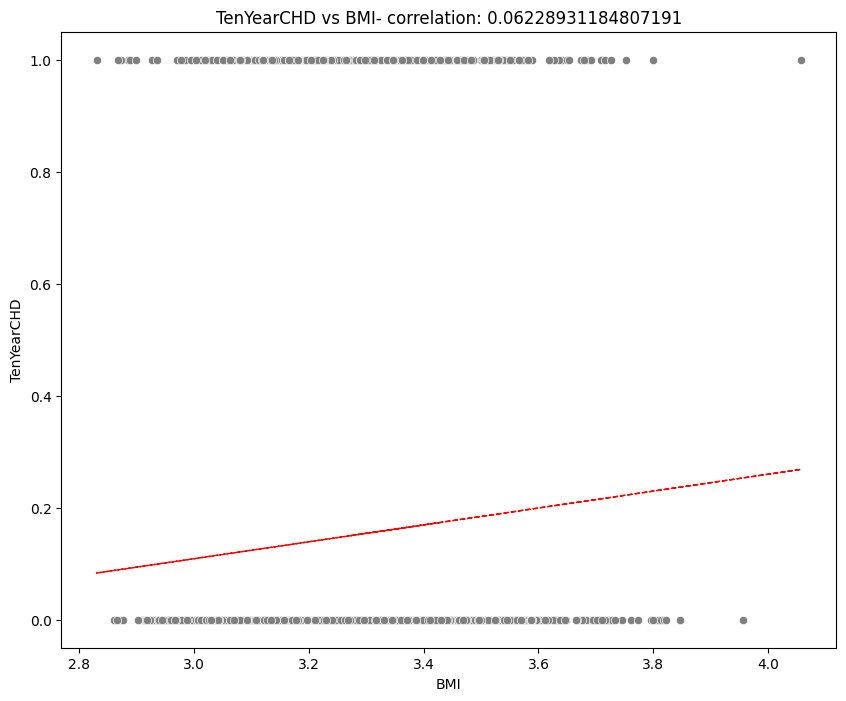

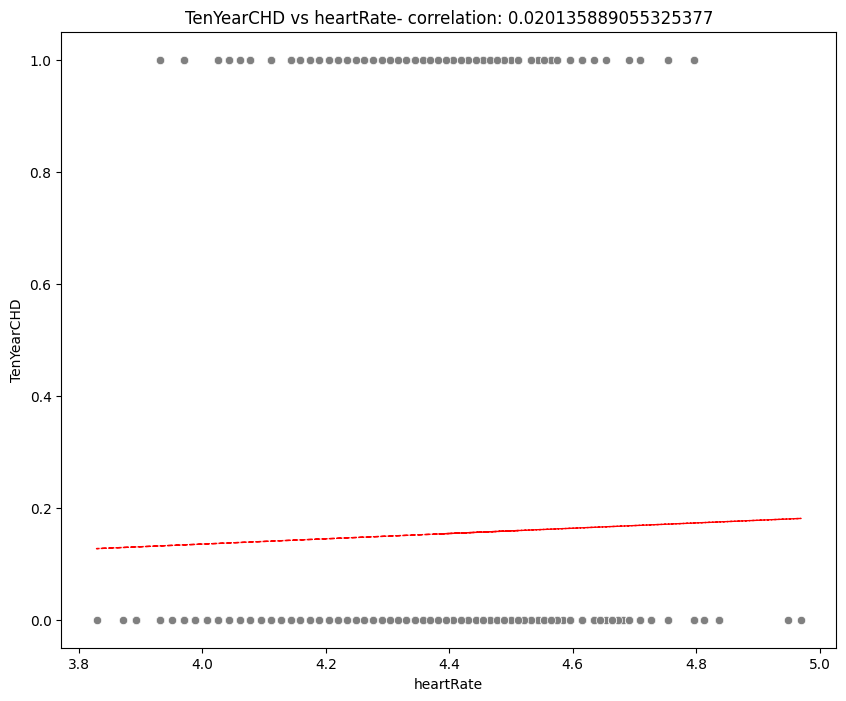

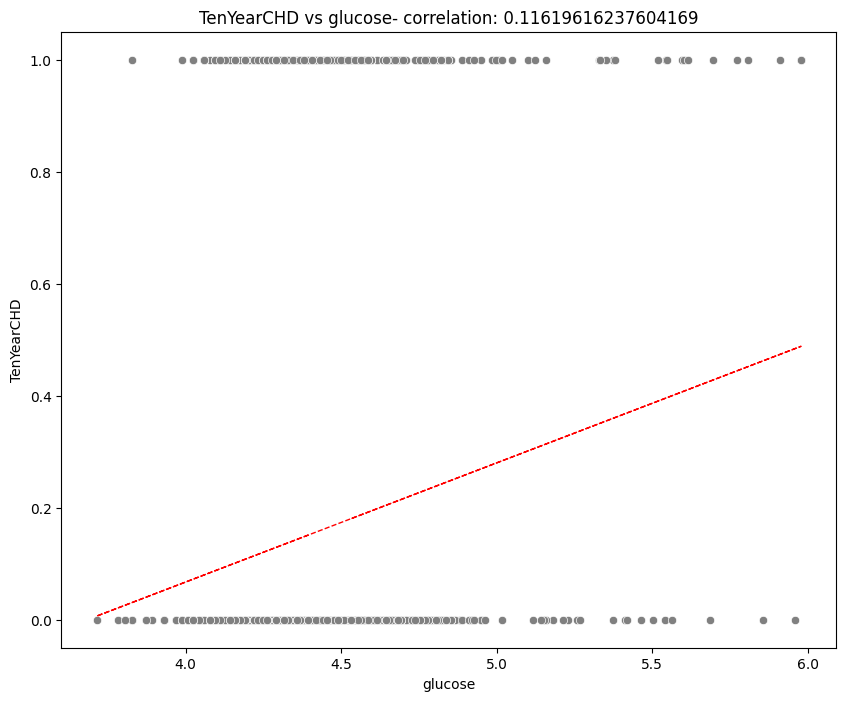

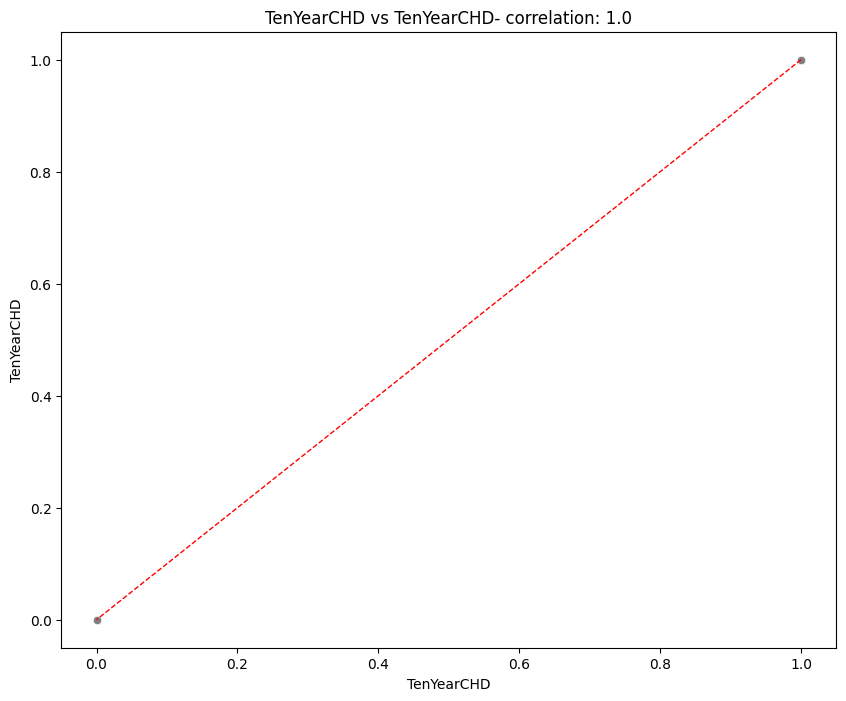

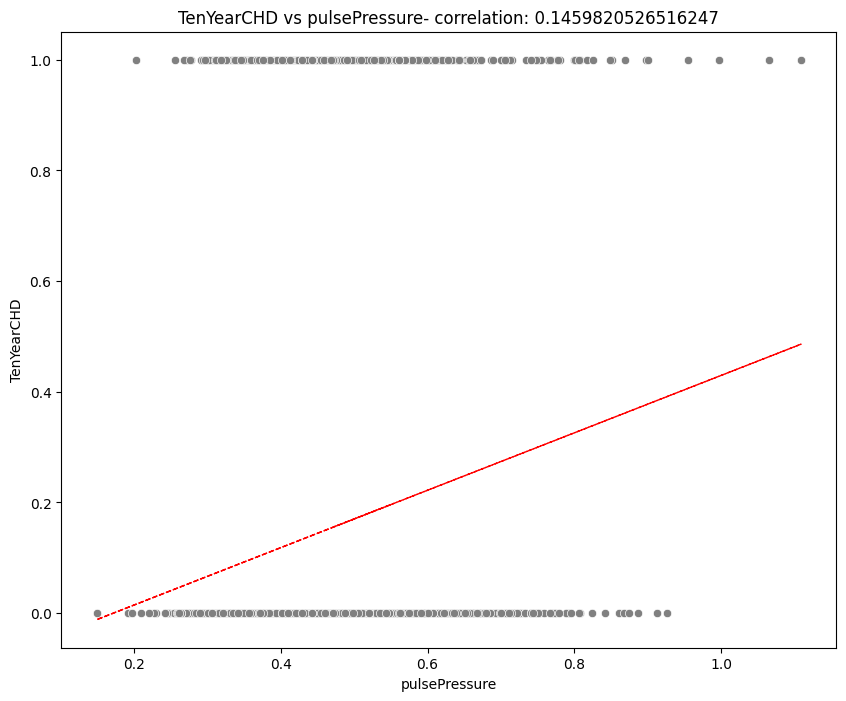

In [79]:
# Select your features wisely to avoid overfitting
for col in df.describe().columns.tolist():
    fig = plt.figure(figsize=(10, 8))
    ax = fig.gca()
    feature = df[col]
    label = df['TenYearCHD']
    correlation = feature.corr(label)
    sns.scatterplot(x=feature, y=label, color="gray")
    plt.xlabel(col)
    plt.ylabel('TenYearCHD')
    ax.set_title('TenYearCHD vs ' + col + '- correlation: ' + str(correlation))
    z = np.polyfit(df[col], df['TenYearCHD'], 1)
    y_hat = np.poly1d(z)(df[col])
    plt.plot(df[col], y_hat, "r--", lw=1)
    plt.show()

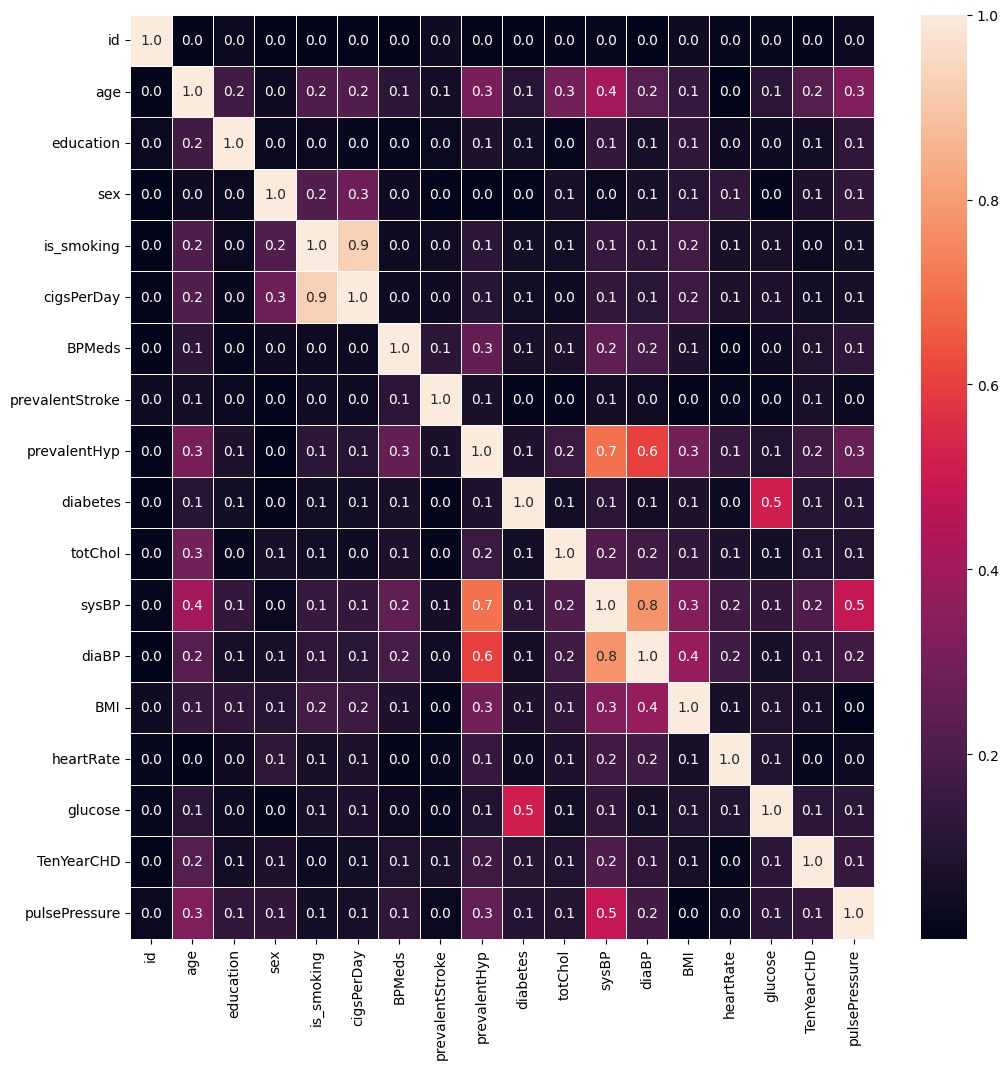

In [80]:
f,ax = plt.subplots(figsize=(12, 12))
sns.heatmap(abs(round(df.corr(),3)), annot=True, linewidths=.5, fmt= '.1f',ax=ax)
plt.show()

### 5. Data Transformation

Before Applying Transformation


Text(0.5, 1.0, 'Distribution of pulsePressure')

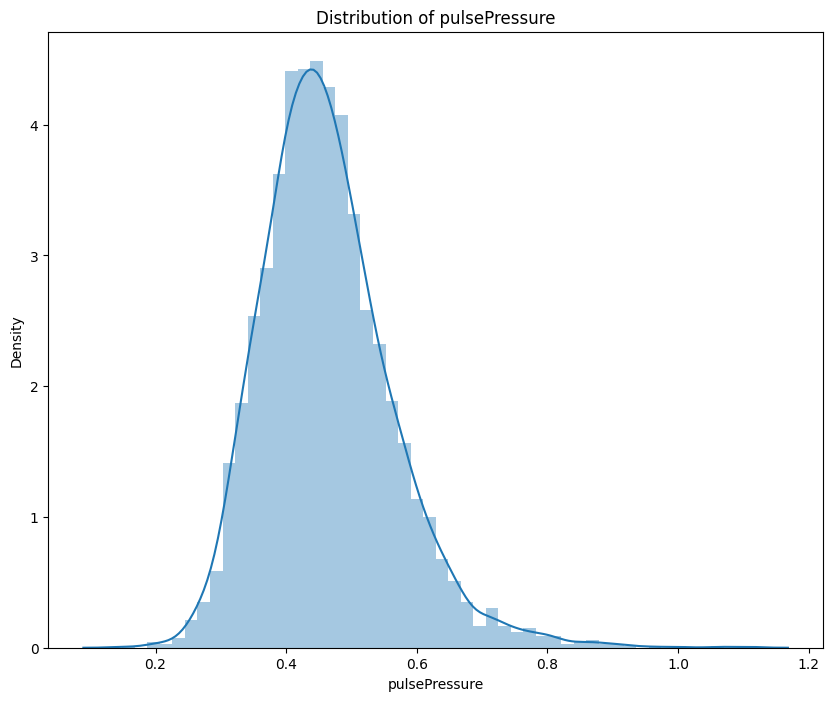

In [81]:
plt.figure(figsize=(10,8))
print("Before Applying Transformation")
sns.distplot(df['pulsePressure'])
plt.title('Distribution of pulsePressure')

((array([-3.53427553, -3.29263892, -3.15912694, ...,  3.15912694,
          3.29263892,  3.53427553], shape=(3390,)),
  array([0.14895586, 0.19166742, 0.19753098, ..., 0.99780759, 1.06471074,
         1.10897508], shape=(3390,))),
 (np.float64(0.09881710532327304),
  np.float64(0.46253294418818647),
  np.float64(0.9803376025811831)))

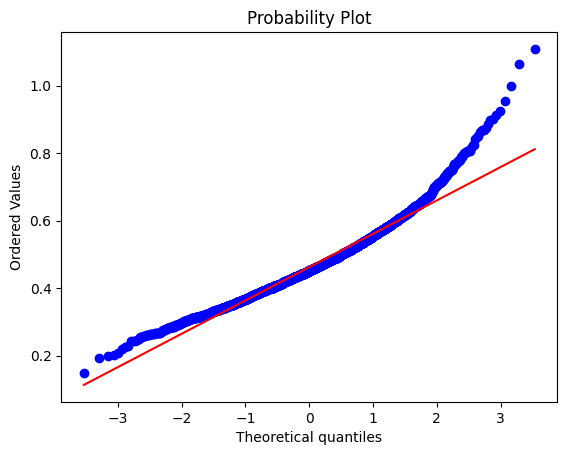

In [82]:
stats.probplot(df['pulsePressure'],dist='norm',plot=pylab)

In [83]:
df['pulsePressure']=np.log(df['pulsePressure']+1)

In [84]:
df.columns

Index(['id', 'age', 'education', 'sex', 'is_smoking', 'cigsPerDay', 'BPMeds',
       'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP',
       'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD', 'pulsePressure'],
      dtype='object')

In [85]:
final_df = df[['age', 'education', 'sex','cigsPerDay', 'BPMeds',
               'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol',
               'BMI', 'heartRate', 'glucose', 'pulsePressure', 'TenYearCHD']]

<Axes: >

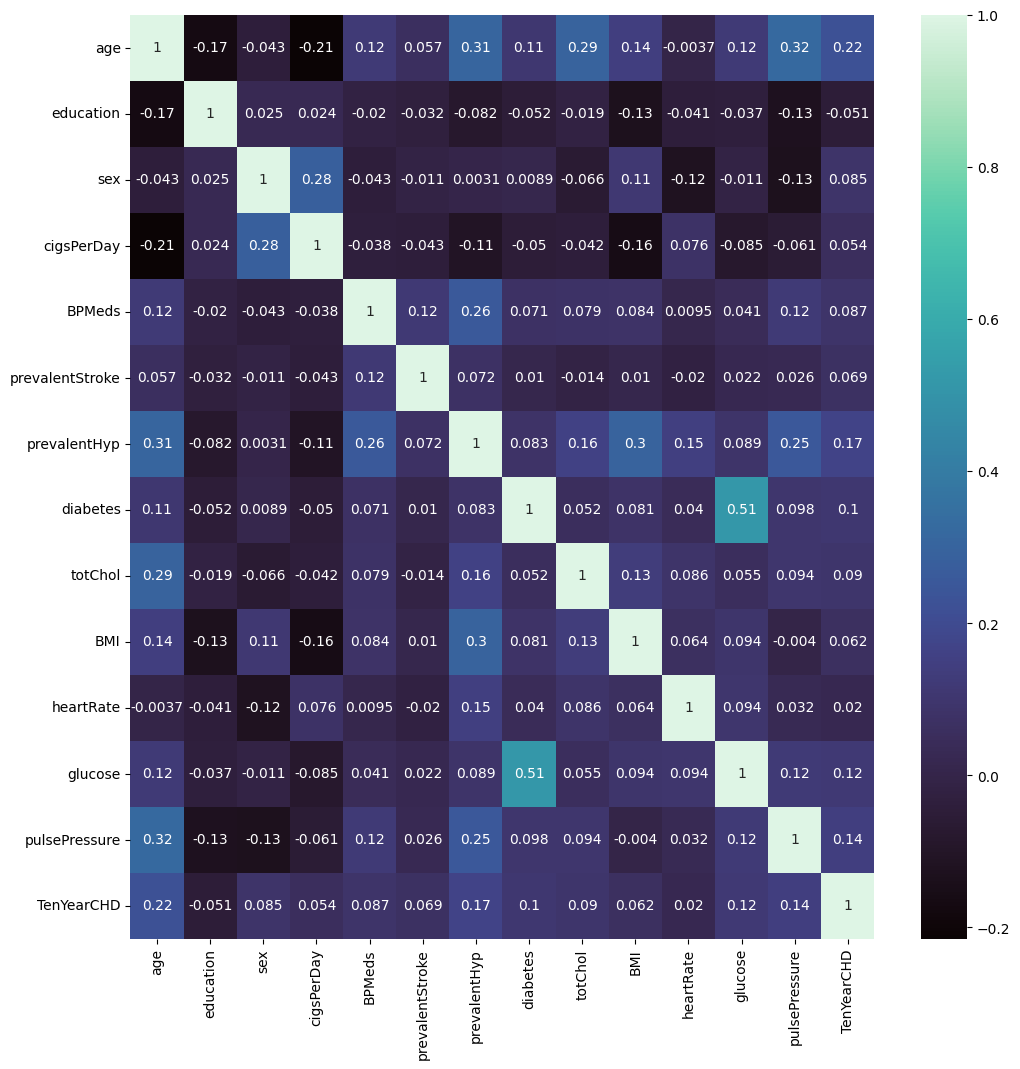

In [86]:
# check for heatmap if anything remains to avoid multicollinearity
plt.figure(figsize=(12,12))
correlation = final_df.corr()
sns.heatmap((correlation), annot=True, cmap=sns.color_palette("mako", as_cmap=True))

### 6. Data Scaling

In [87]:
# Scaling your data
x= final_df.drop('TenYearCHD',axis=1)
y= final_df[['TenYearCHD']]
print(x.shape)
print(y.shape)

(3390, 13)
(3390, 1)


In [88]:
# Creating object
std_regressor= StandardScaler()

# Fit and Transform
x= std_regressor.fit_transform(x)

##### Which method have you used to scale you data and why?

* StandardScaler scales the data so that the mean is 0 and the standard deviation is 1. It is a commonly used method for scaling data in machine learning because it preserves the shape of the original distribution and is suitable for most machine learning algorithms, especially those that use distance-based measures. StandardScaler is also useful for the features in the data have significantly different scales because it can help to make the features more comparable.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

**NO it's not needed.**

* However, in this case of the cardiovascular risk prediction dataset, it is not necessary to perform dimensionality reduction. This is because the dataset has a relatively small number of features compared to the number of samples, which means that the risk of overfitting is low. Additionally, the dataset is relatively small, so the training time for machine learning models would not be a significant issue.

### 8. Data Splitting

In [89]:
# Split your data to train and test. Choose Splitting ratio wisely.
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=10)

In [90]:
print(f'The shape of x_train is: {x_train.shape}')
print(f'The shape of y_train is: {y_train.shape}')
print(f'The shape of x_test is: {x_test.shape}')
print(f'The shape of y_test is: {y_test.shape}')

The shape of x_train is: (2712, 13)
The shape of y_train is: (2712, 1)
The shape of x_test is: (678, 13)
The shape of y_test is: (678, 1)


##### What data splitting ratio have you used and why?

* To prevent overfitting and improve model generalization performance, we allocated 80% of the data to the training set and 20% to the testing set. The train_test_split function from the scikit-learn library was used for this purpose, as it's a common approach for training and testing the model on different data samples.

### 9. Handling Imbalanced Dataset

In [91]:
print(df.TenYearCHD.value_counts())

TenYearCHD
0    2879
1     511
Name: count, dtype: int64


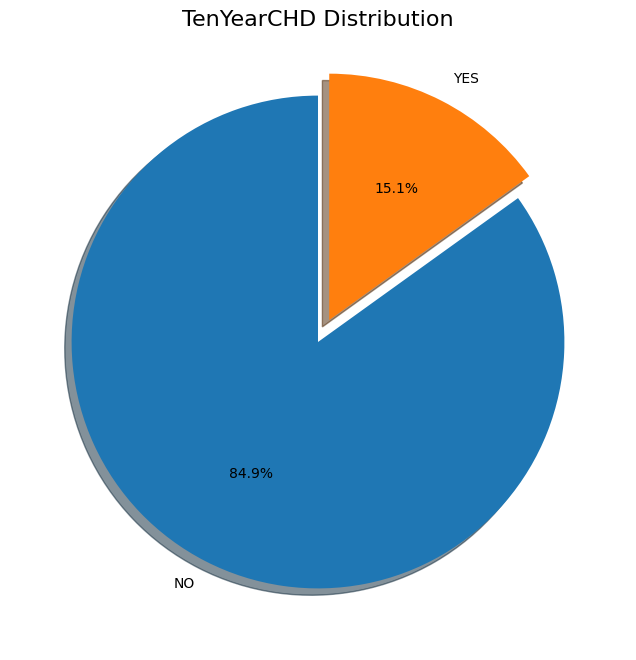

In [92]:
# calculate value counts of 'TenYearCHD' column
counts =df['TenYearCHD'].value_counts()


labels = ['NO','YES']
plt.figure(figsize=(10,8))
plt.pie(counts, labels=labels, autopct= "%1.1f%%",
        startangle=90, shadow=True, explode=[0,.1])
plt.title('TenYearCHD Distribution', fontsize=16)
plt.show()

In [93]:
# Handling Imbalanced Dataset (If needed)
smote = SMOTE(random_state=10)

x_resampled, y_resampled = smote.fit_resample(x, y)

print('Original dataset shape:', df.shape)
print('Resampled dataset shape:', x_resampled.shape)

print('Class distribution in the resampled dataset:', y_resampled.value_counts())

Original dataset shape: (3390, 18)
Resampled dataset shape: (5758, 13)
Class distribution in the resampled dataset: TenYearCHD
0             2879
1             2879
Name: count, dtype: int64


In [94]:
x_train,x_test,y_train,y_test = train_test_split(x_resampled, y_resampled,test_size=0.2,random_state=10)


In [95]:
print(f'The shape of x_train is: {x_train.shape}')
print(f'The shape of y_train is: {y_train.shape}')
print(f'The shape of x_test is: {x_test.shape}')
print(f'The shape of y_test is: {y_test.shape}')

The shape of x_train is: (4606, 13)
The shape of y_train is: (4606, 1)
The shape of x_test is: (1152, 13)
The shape of y_test is: (1152, 1)


## ***7. ML Model Implementation***

### ML Model - 1 Logistic Regression

In [96]:
def model_metrics(y_train, y_test, train_preds, test_preds):
    train_accuracy = accuracy_score(y_train, train_preds)
    test_accuracy = accuracy_score(y_test, test_preds)
    train_precision = precision_score(y_train, train_preds)
    test_precision = precision_score(y_test, test_preds)
    train_recall = recall_score(y_train, train_preds)
    test_recall = recall_score(y_test, test_preds)
    train_roc_auc = roc_auc_score(y_train, train_preds)
    test_roc_auc = roc_auc_score(y_test, test_preds)

    print(f"{'Train Accuracy':<20}{train_accuracy:.4f}")
    print(f"{'Test Accuracy':<20}{test_accuracy:.4f}")
    print(f"{'Train Precision':<20}{train_precision:.4f}")
    print(f"{'Test Precision':<20}{test_precision:.4f}")
    print(f"{'Train Recall':<20}{train_recall:.4f}")
    print(f"{'Test Recall':<20}{test_recall:.4f}")
    print(f"{'Train ROC AUC':<20}{train_roc_auc:.4f}")
    print(f"{'Test ROC AUC':<20}{test_roc_auc:.4f}")
    print("-"*50)

    train_confusion_matrix = confusion_matrix(y_train, train_preds)
    test_confusion_matrix = confusion_matrix(y_test, test_preds)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    labels = ['0', '1']
    sns.heatmap(train_confusion_matrix, annot=True, cmap='Blues', ax=axes[0], fmt="d", xticklabels=labels, yticklabels=labels)
    axes[0].set_xlabel('Predicted labels')
    axes[0].set_ylabel('True labels')
    axes[0].set_title('Train Confusion Matrix')
    sns.heatmap(test_confusion_matrix, annot=True, cmap='Blues', ax=axes[1], fmt="d", xticklabels=labels, yticklabels=labels)
    axes[1].set_xlabel('Predicted labels')
    axes[1].set_ylabel('True labels')
    axes[1].set_title('Test Confusion Matrix')

    plt.show()

In [97]:
# ML Model - 1 Implementation
logistic_classifier= LogisticRegression()
# Fit the Algorithm
logistic_classifier.fit(x_train,y_train)
# Predict on the model
y_train_logistic_pred= logistic_classifier.predict(x_train)
y_test_logistic_pred= logistic_classifier.predict(x_test)


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Train Accuracy      0.6743
Test Accuracy       0.6545
Train Precision     0.6714
Test Precision      0.6254
Train Recall        0.6973
Test Recall         0.6891
Train ROC AUC       0.6741
Test ROC AUC        0.6560
--------------------------------------------------


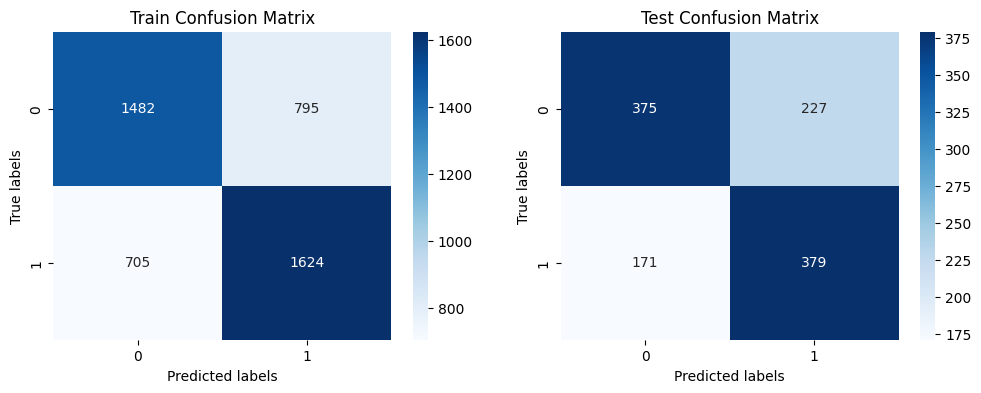

In [98]:
# Visualizing evaluation Metric Score chart
model_metrics(y_train, y_test, y_train_logistic_pred, y_test_logistic_pred)

#### 2. Cross- Validation & Hyperparameter Tuning

In [99]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
from sklearn.model_selection import cross_val_score

logistic_regression = LogisticRegression()
# set up the parameter grid for hyperparameter tuning
param_grid = {'penalty': ['l1', 'l2'],
              'C': [0.1, 1.0, 10.0],
              'solver': ['liblinear', 'saga']}
# Fit the Algorithm
grid_search = GridSearchCV(logistic_regression, param_grid, cv=5)
grid_search.fit(x_train, y_train)
# get the best hyperparameters and print them
best_params = grid_search.best_params_
print('Best hyperparameters:', best_params)
# use the best hyperparameters to fit the model and make predictions
logistic_regression_best = LogisticRegression(**best_params)
# perform cross-validation on the model with the best hyperparameters
cv_scores = cross_val_score(logistic_regression_best, x_train, y_train, cv=5)
# fit the final model using all the training data and the best hyperparameters
logistic_regression_best.fit(x_train, y_train)
y_train_logistic_pred_cv = logistic_regression_best.predict(x_train)
y_test_logistic_pred_cv  = logistic_regression_best.predict(x_test)
y_score_logistic_pred_cv = logistic_regression_best.predict_proba(x_test)[:, 1]

Best hyperparameters: {'C': 0.1, 'penalty': 'l1', 'solver': 'saga'}


Train Accuracy      0.6759
Test Accuracy       0.6571
Train Precision     0.6720
Test Precision      0.6273
Train Recall        0.7012
Test Recall         0.6945
Train ROC AUC       0.6756
Test ROC AUC        0.6587
--------------------------------------------------


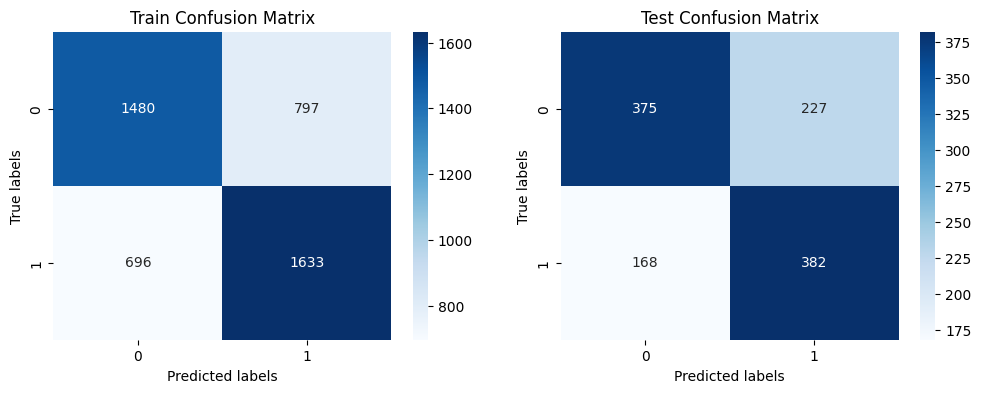

In [100]:
model_metrics(y_train, y_test, y_train_logistic_pred_cv, y_test_logistic_pred_cv)


##### Which hyperparameter optimization technique have you used and why?

* GridSearchCV is an effective technique for optimizing the hyperparameters of machine learning models. By evaluating all possible combinations of hyperparameters and their values, GridSearchCV selects the best combination based on performance calculation, resulting in more accurate results and improved model performance.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

* We optimized our ML model's performance by using GridSearchCV to search for the best hyperparameters. This technique tried all possible combinations of hyperparameters and provided the most accurate results by selecting the best values.

* But still we are not able to see any improvement in results. we got Test accuracy of 67.97%. Test Precision and Test Recall 66.55% and 69.27%.Also the area under curve (ROC AUC) 0.68 that's not enough.

* So we will go for other model such as Logistic Regression, Random Forest and XGBoost to improve accuracy and AUC score.

### ML Model - 2  Random Forest Classifier


In [101]:
# ML Model - 2  Implementation
random_forest = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_split=2, min_samples_leaf=1)

# Fit the Algorithm
random_forest.fit(x_train, y_train)

# Predict on the model
y_train_rf_pred = random_forest.predict(x_train)
y_test_rf_pred = random_forest.predict(x_test)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Train Accuracy      0.9325
Test Accuracy       0.8325
Train Precision     0.9065
Test Precision      0.7829
Train Recall        0.9661
Test Recall         0.8982
Train ROC AUC       0.9321
Test ROC AUC        0.8353
--------------------------------------------------


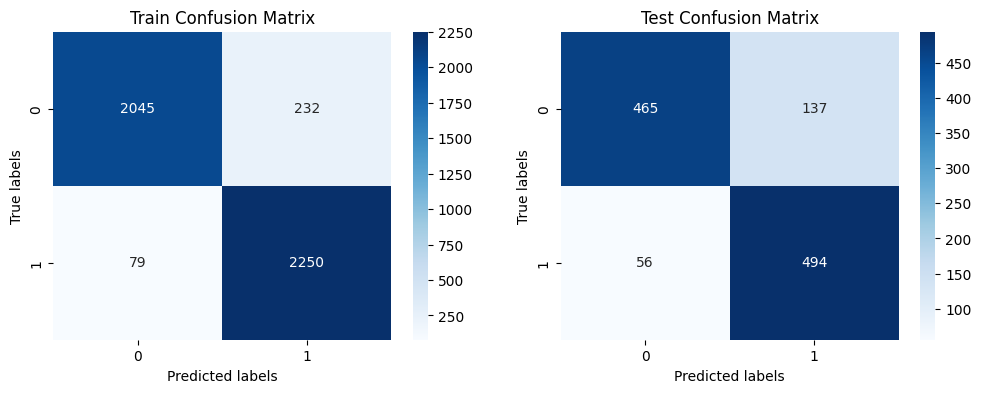

In [102]:
# Visualizing evaluation Metric Score chart
model_metrics(y_train, y_test, y_train_rf_pred, y_test_rf_pred)

#### 2. Cross- Validation & Hyperparameter Tuning

In [103]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
random_forest = RandomForestClassifier()
param_grid = {'n_estimators': [100, 200, 300],
              'max_depth': [5, 10, 15, None],
              'min_samples_split': [2, 5, 10],
              'min_samples_leaf': [1, 2, 4]}
# Fit the Algorithm
grid_search = GridSearchCV(random_forest, param_grid, cv=5)
grid_search.fit(x_train, y_train)
# get the best hyperparameters and print them
best_params = grid_search.best_params_
print('Best hyperparameters:', best_params)
# use the best hyperparameters to fit the model to the training data
random_forest_best = RandomForestClassifier(**best_params)
random_forest_best.fit(x_train, y_train)
# Predict on the model
y_train_rf_pred_gs = random_forest_best.predict(x_train)
y_test_rf_pred_gs  = random_forest_best.predict(x_test)
y_score_rf_pred_gs = random_forest_best.predict_proba(x_test)[:, 1]

Best hyperparameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}


Train Accuracy      1.0000
Test Accuracy       0.8984
Train Precision     1.0000
Test Precision      0.8701
Train Recall        1.0000
Test Recall         0.9255
Train ROC AUC       1.0000
Test ROC AUC        0.8996
--------------------------------------------------


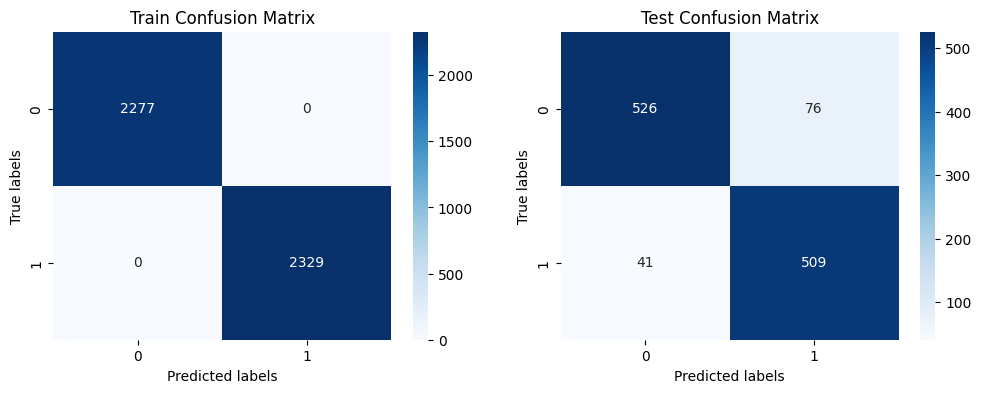

In [104]:
# Visualizing evaluation Metric Score chart
model_metrics(y_train, y_test, y_train_rf_pred_gs, y_test_rf_pred_gs)

### ML Model - 3 XGBoost Classifier

In [105]:
# ML Model - 3 Implementation
xgb = XGBClassifier()
# Fit the Algorithm
xgb.fit(x_train, y_train)
# Predict on the model
y_train_xgb_pred = xgb.predict(x_train)
y_test_xgb_pred = xgb.predict(x_test)


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Train Accuracy      0.9950
Test Accuracy       0.8932
Train Precision     1.0000
Test Precision      0.8991
Train Recall        0.9901
Test Recall         0.8745
Train ROC AUC       0.9951
Test ROC AUC        0.8924
--------------------------------------------------


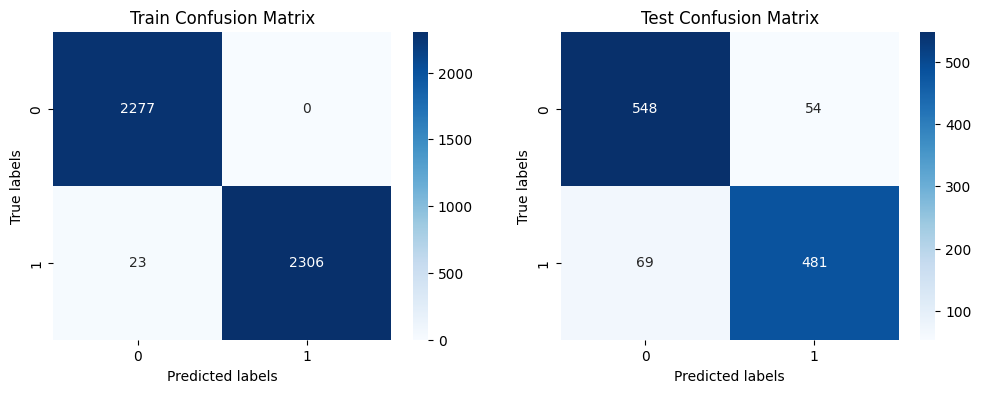

In [106]:
# Visualizing evaluation Metric Score chart
model_metrics(y_train, y_test, y_train_xgb_pred, y_test_xgb_pred)

#### 2. Cross- Validation & Hyperparameter Tuning

In [107]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# set up the parameter grid for hyperparameter tuning
param_grid = {'max_depth': [3, 5, 7],
              'learning_rate': [0.01, 0.1, 0.3],
              'n_estimators': [50, 100, 200]}
# Fit the Algorithm
grid_search = GridSearchCV(xgb, param_grid, cv=5, n_jobs=-1)
grid_search.fit(x_train, y_train)
# print the best hyperparameters
print('Best hyperparameters:', grid_search.best_params_)
# Predict on the model
best_estimator = grid_search.best_estimator_
y_train_xgb_pred_gs = best_estimator.predict(x_train)
y_test_xgb_pred_gs  = best_estimator.predict(x_test)
y_score_xgb_pred_gs = best_estimator.predict_proba(x_test)[:, 1]

Best hyperparameters: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200}


Train Accuracy      0.9915
Test Accuracy       0.9036
Train Precision     1.0000
Test Precision      0.9103
Train Recall        0.9833
Test Recall         0.8855
Train ROC AUC       0.9916
Test ROC AUC        0.9029
--------------------------------------------------


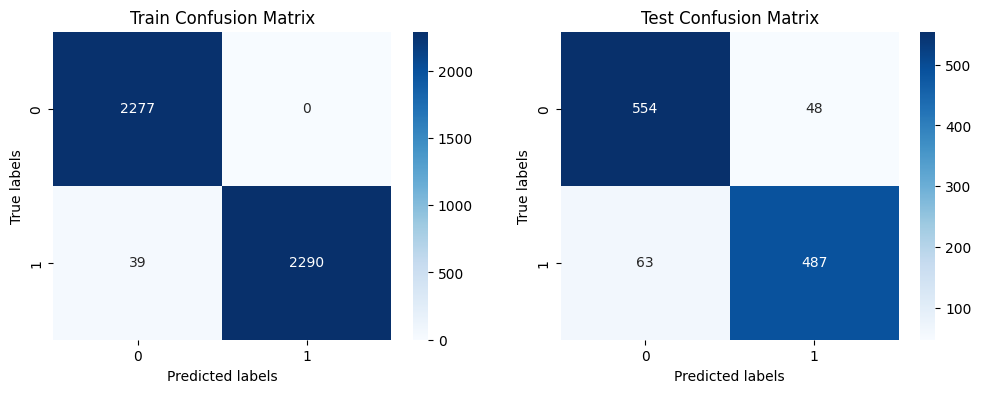

In [108]:
# Visualizing evaluation Metric Score chart
model_metrics(y_train, y_test, y_train_xgb_pred_gs, y_test_xgb_pred_gs)

### ML Model - 4) K-Nearest Neighbors (KNN)

In [109]:
# ML Model - 4 Implementation
knn = KNeighborsClassifier(n_neighbors=5)

# Fit the Algorithm
knn.fit(x_train, y_train)

# Predict on the model
y_train_knn_pred = knn.predict(x_train)
y_test_knn_pred = knn.predict(x_test)

Train Accuracy      0.8671
Test Accuracy       0.7917
Train Precision     0.7972
Test Precision      0.7061
Train Recall        0.9888
Test Recall         0.9655
Train ROC AUC       0.8657
Test ROC AUC        0.7992
--------------------------------------------------


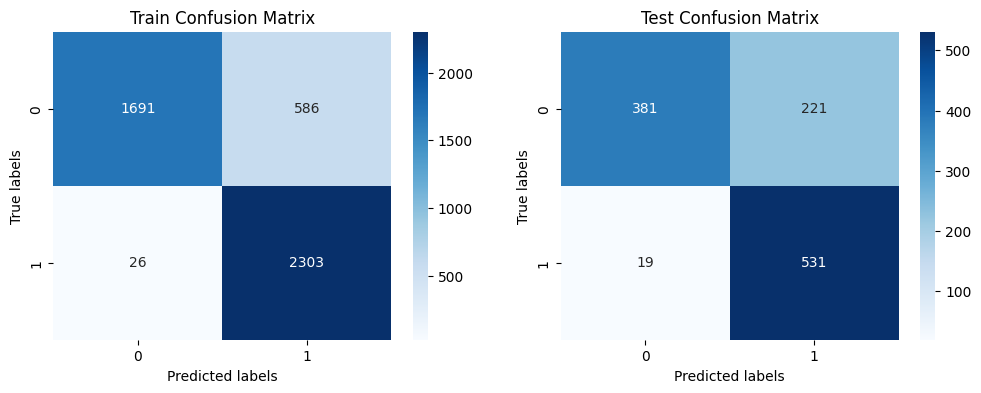

In [110]:
# Visualizing evaluation Metric Score chart
model_metrics(y_train, y_test, y_train_knn_pred, y_test_knn_pred)

**2. Cross- Validation & Hyperparameter Tuning**

In [111]:
# ML Model - 4  Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# set up the parameter grid for hyperparameter tuning
param_grid = {'n_neighbors': [3, 5, 7],
              'weights': ['uniform', 'distance']}
# Fit the Algorithm
grid_search = GridSearchCV(knn, param_grid, cv=5)
grid_search.fit(x_train, y_train)
# get the best hyperparameters and print them
best_params = grid_search.best_params_
print('Best hyperparameters:', best_params)
# train the classifier with the best hyperparameters on the full training set
knn_best = KNeighborsClassifier(**best_params)
knn_best.fit(x_train, y_train)
# Predict on the model
y_test_knn_pred_gs  = knn_best.predict(x_test)
y_train_knn_pred_gs = knn_best.predict(x_train)
y_score_knn_pred_gs = knn_best.predict_proba(x_test)[:, 1]


Best hyperparameters: {'n_neighbors': 3, 'weights': 'distance'}


Train Accuracy      1.0000
Test Accuracy       0.8194
Train Precision     1.0000
Test Precision      0.7317
Train Recall        1.0000
Test Recall         0.9818
Train ROC AUC       1.0000
Test ROC AUC        0.8265
--------------------------------------------------


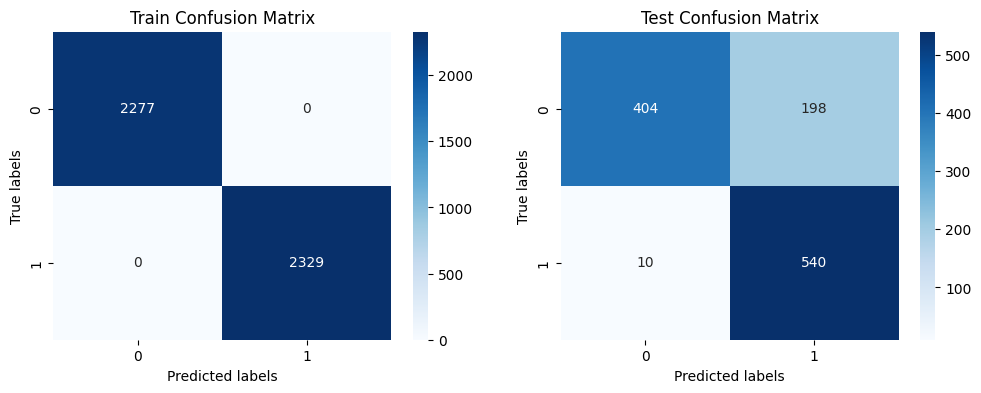

In [112]:
# Visualizing evaluation Metric Score chart
model_metrics(y_train, y_test, y_train_knn_pred_gs, y_test_knn_pred_gs)

### ML Model - 5) Support Vector Machine Classifier (SVC)

In [113]:
# ML Model - 5 Implementation
svc = SVC(kernel='rbf', C=1, gamma='scale')

# Fit the Algorithm
svc.fit(x_train, y_train)

# Predict on the model
y_train_svc_pred = svc.predict(x_train)
y_test_svc_pred = svc.predict(x_test)


**1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.**

Train Accuracy      0.7553
Test Accuracy       0.7023
Train Precision     0.7394
Test Precision      0.6651
Train Recall        0.7969
Test Recall         0.7582
Train ROC AUC       0.7548
Test ROC AUC        0.7047
--------------------------------------------------


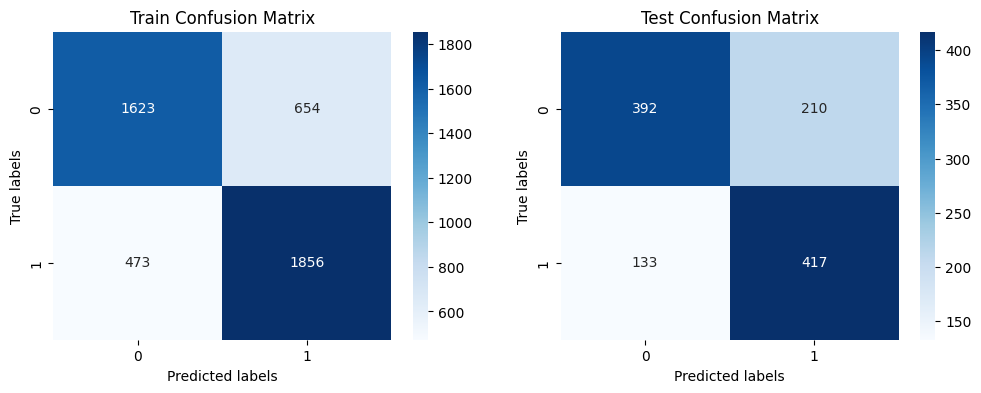

In [114]:
# Visualizing evaluation Metric Score chart
model_metrics(y_train, y_test, y_train_svc_pred, y_test_svc_pred)

**2. Cross- Validation & Hyperparameter Tuning**

In [115]:
# ML Model - 5  Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
svc = SVC(probability=True)
# set up the parameter grid for hyperparameter tuning
param_grid = {'C': [0.1, 1, 10],
              'kernel': ['linear', 'rbf'],
              'gamma': ['scale', 'auto']}
# perform a grid search with 5-fold cross-validation to find the best hyperparameters
grid_search = GridSearchCV(svc, param_grid, cv=5)
grid_search.fit(x_train, y_train)
# get the best hyperparameters and print them
best_params = grid_search.best_params_
print('Best hyperparameters:', best_params)
# train the classifier with the best hyperparameters on the full training set
svc_best = SVC(**best_params, probability=True)
svc_best.fit(x_train, y_train)
# Predict on the model
y_test_svc_pred_gs = svc_best.predict(x_test)
y_train_svc_pred_gs = svc_best.predict(x_train)
y_score_svc_pred_gs = svc_best.predict_proba(x_test)[:, 1]


Best hyperparameters: {'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}


Train Accuracy      0.8604
Test Accuracy       0.7899
Train Precision     0.8257
Test Precision      0.7369
Train Recall        0.9176
Test Recall         0.8709
Train ROC AUC       0.8597
Test ROC AUC        0.7934
--------------------------------------------------


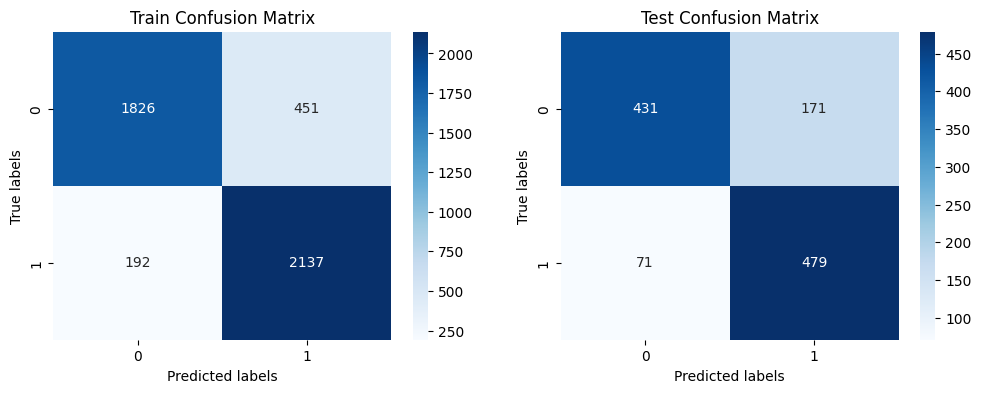

In [116]:
# Visualizing evaluation Metric Score chart
model_metrics(y_train, y_test, y_train_svc_pred_gs, y_test_svc_pred_gs)

### ML Model - 6) Naive Bayes Classifier

In [117]:
# ML Model - 6 Implementation
# create an instance of the Gaussian Naive Bayes classifier
nb = GaussianNB()

# Fit the Algorithm
nb.fit(x_train, y_train)

# Predict on the model
y_train_nb_pred = nb.predict(x_train)
y_test_nb_pred = nb.predict(x_test)

**1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.**

Train Accuracy      0.5634
Test Accuracy       0.5694
Train Precision     0.7461
Test Precision      0.6985
Train Recall        0.2070
Test Recall         0.1727
Train ROC AUC       0.5675
Test ROC AUC        0.5523
--------------------------------------------------


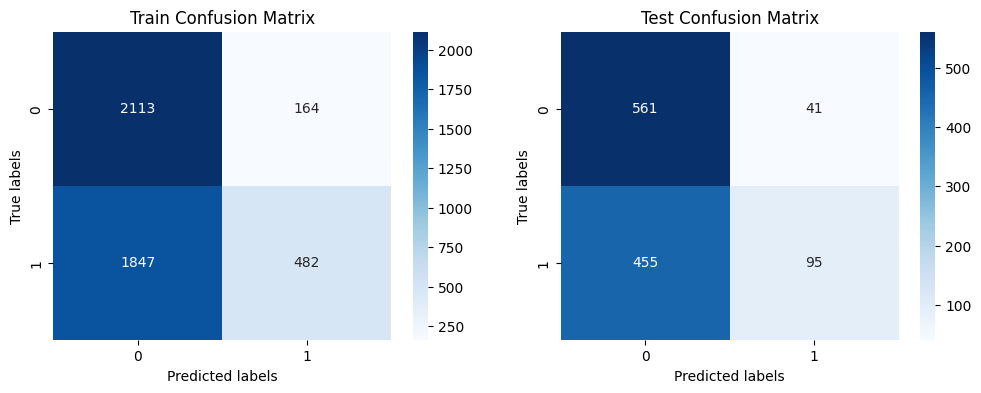

In [118]:
# Visualizing evaluation Metric Score chart
model_metrics(y_train, y_test, y_train_nb_pred, y_test_nb_pred)


**2. Cross- Validation & Hyperparameter Tuning**

In [119]:
# ML Model - 6  Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
from sklearn.model_selection import cross_val_score
# create an instance of the Gaussian Naive Bayes classifier
nb = GaussianNB()
# set up the parameter grid for hyperparameter tuning
param_grid = {'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]}
# perform a grid search with cross-validation to find the best hyperparameters
grid_search = GridSearchCV(nb, param_grid, cv=5)
grid_search.fit(x_train, y_train)
# get the best hyperparameters and print them
best_params = grid_search.best_params_
print('Best hyperparameters:', best_params)
# create a new instance of the classifier using the best hyperparameters
nb_best = GaussianNB(**best_params)
# evaluate the classifier using cross-validation
scores = cross_val_score(nb_best, x_train, y_train, cv=5)
# print the cross-validation scores
print('Cross-validation scores:', scores)
# train the classifier on the entire training set using the best hyperparameters
nb_best.fit(x_train, y_train)
# make predictions on the training and test sets
y_train_nb_pred_gs = nb_best.predict(x_train)
y_test_nb_pred_gs = nb_best.predict(x_test)
y_score_nb_pred_gs = nb_best.predict_proba(x_test)[:, 1]

Best hyperparameters: {'var_smoothing': 1e-09}
Cross-validation scores: [0.55856833 0.55917481 0.55157438 0.56243214 0.58631922]


Train Accuracy      0.5634
Test Accuracy       0.5694
Train Precision     0.7461
Test Precision      0.6985
Train Recall        0.2070
Test Recall         0.1727
Train ROC AUC       0.5675
Test ROC AUC        0.5523
--------------------------------------------------


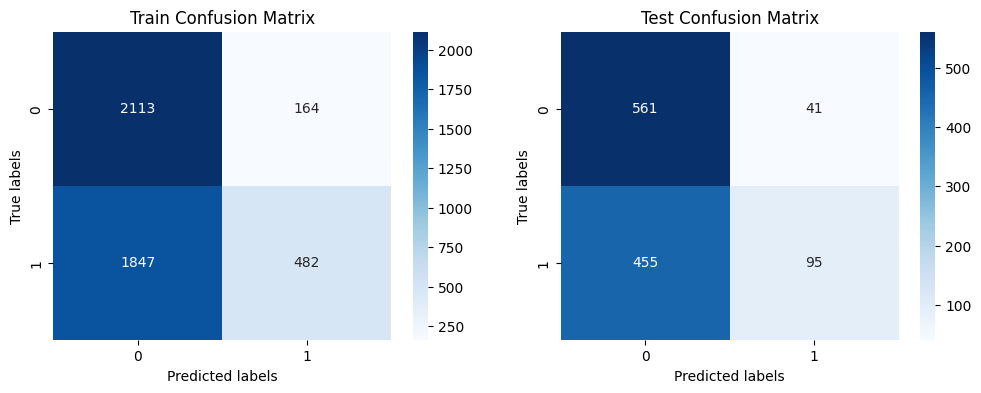

In [120]:
# Visualizing evaluation Metric Score chart
model_metrics(y_train, y_test, y_train_nb_pred_gs, y_test_nb_pred_gs)

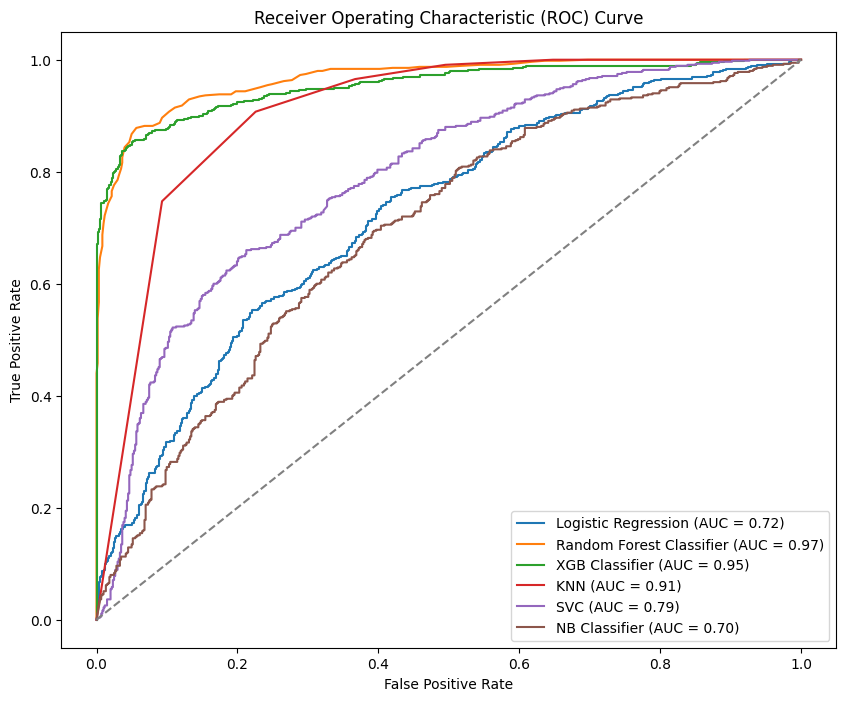

In [121]:
# define the classifiers
classifiers = [ ("Logistic Regression", LogisticRegression()),
                ("Random Forest Classifier", RandomForestClassifier()),
                ("XGB Classifier", XGBClassifier()),
                ("KNN", KNeighborsClassifier()),
                ("SVC", SVC(probability=True)),
                ("NB Classifier", GaussianNB())]

# iterate through classifiers and plot ROC curves
plt.figure(figsize=(10, 8))
for name, classifier in classifiers:
    classifier.fit(x_train, y_train)
    y_score = classifier.predict_proba(x_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

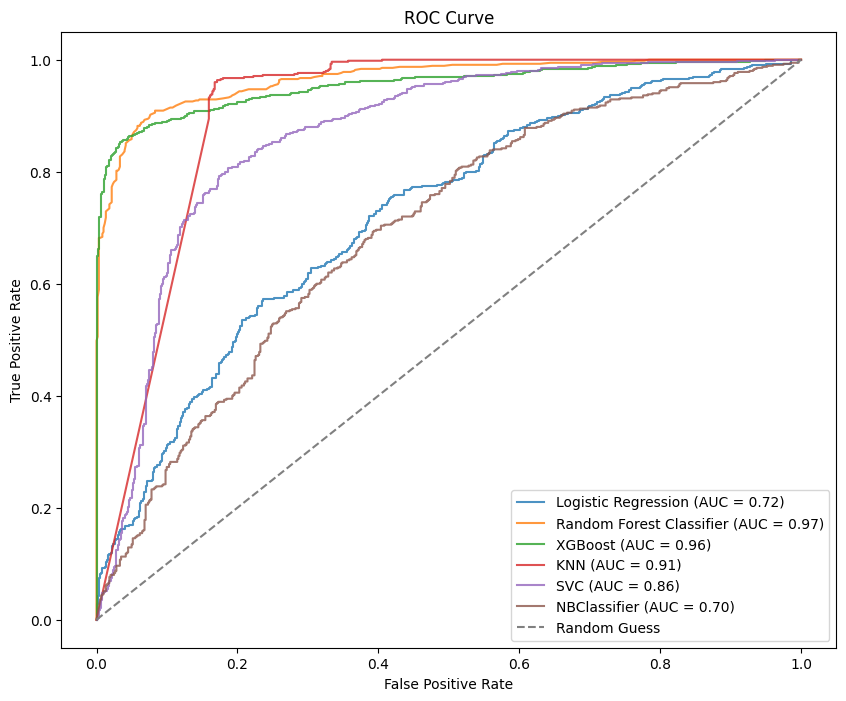

In [122]:
# after cross validation and hyperparameter tuning
Model = ["Logistic Regression", "Random Forest Classifier", "XGBoost", "KNN", "SVC","NBClassifier"]
Y_SCORE = [y_score_logistic_pred_cv, y_score_rf_pred_gs, y_score_xgb_pred_gs,
           y_score_knn_pred_gs, y_score_svc_pred_gs,y_score_nb_pred_gs]

# Create dataframe from the lists
data = {'MODEL': Model, 'Y_SCORE': Y_SCORE}
Metric_df = pd.DataFrame(data)

# plot the ROC curves for each model
plt.figure(figsize=(10, 8))
for i, row in Metric_df.iterrows():
    fpr, tpr, _ = roc_curve(y_test, row['Y_SCORE'])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{row['MODEL']} (AUC = {roc_auc:.2f})", alpha=0.8)
plt.plot([0, 1], [0, 1], color='grey', linestyle='--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

In [123]:
# Storing metrics in order to make dataframe of metrics
# (after cross validation and hyperparameter tuning)
Model          = ["Logistic Regression", "Random Forest Classifier", "XGBoost", "KNN", "SVC", "NBClassifier"]
Test_Accuracy  = [0.6571,0.9036,0.9019,0.8194,0.7899,0.5694]
Test_Precision = [0.6273,0.8791,0.8951,0.7317,0.7369,0.6985]
Test_Recall    = [0.6945,0.9255,0.9000,0.9818,0.8709,0.1727]
Test_ROC_AUC   = [0.6587,0.9046,0.9018,0.8265,0.7934,0.5523]
# Create dataframe from the lists
data = {'Model' : Model,
        'Test_Accuracy'  : Test_Accuracy,
        'Test_Precision' : Test_Precision,
        'Test_Recall'    : Test_Recall,
        'Test_ROC_AUC'   : Test_ROC_AUC}
Metric_df = pd.DataFrame(data)

# Printing dataframe
Metric_df

,Model,Test_Accuracy,Test_Precision,Test_Recall,Test_ROC_AUC
0,Logistic Regression,0.6571,0.6273,0.6945,0.6587
1,Random Forest Classifier,0.9036,0.8791,0.9255,0.9046
2,XGBoost,0.9019,0.8951,0.9000,0.9018
3,KNN,0.8194,0.7317,0.9818,0.8265
4,SVC,0.7899,0.7369,0.8709,0.7934
5,NBClassifier,0.5694,0.6985,0.1727,0.5523


Based on the results of the different models tested on the cardiovascular risk prediction project, it appears that the Random Forest Classifier and XGBoost models are the best options to use for the final prediction model. Both models have high accuracy scores of 0.9036 and 0.9019 respectively, which is essential for use in real-time prediction systems. Additionally, the precision and recall scores of these models are also high, indicating that they are good at correctly predicting positive and negative cases.

While the KNN model had a relatively high recall score, its accuracy and precision scores were lower than those of the Random Forest Classifier and XGBoost models. Similarly, the SVC model had a lower accuracy and ROC AUC score, indicating that it may not be as suitable for this particular classification problem

However, the 	Random Forest Classifier model has slightly higher test accuracy than the XGBoost, indicating that it may be a better choice for predicting cardiovascular risk.

Additionally, the 	Random Forest Classifier model also has a higher ROC AUC score, suggesting that it has a better ability to distinguish between positive and negative cases. Therefore, based on the results presented, the 	Random Forest Classifier model may be the better choice for predicting cardiovascular risk in this project.

**So, I am choosing Random Forest Classifier model as best fit classification model for Cardiovascular Risk Prediction dataset.**

Text(0.5, 0, 'Relative Importance')

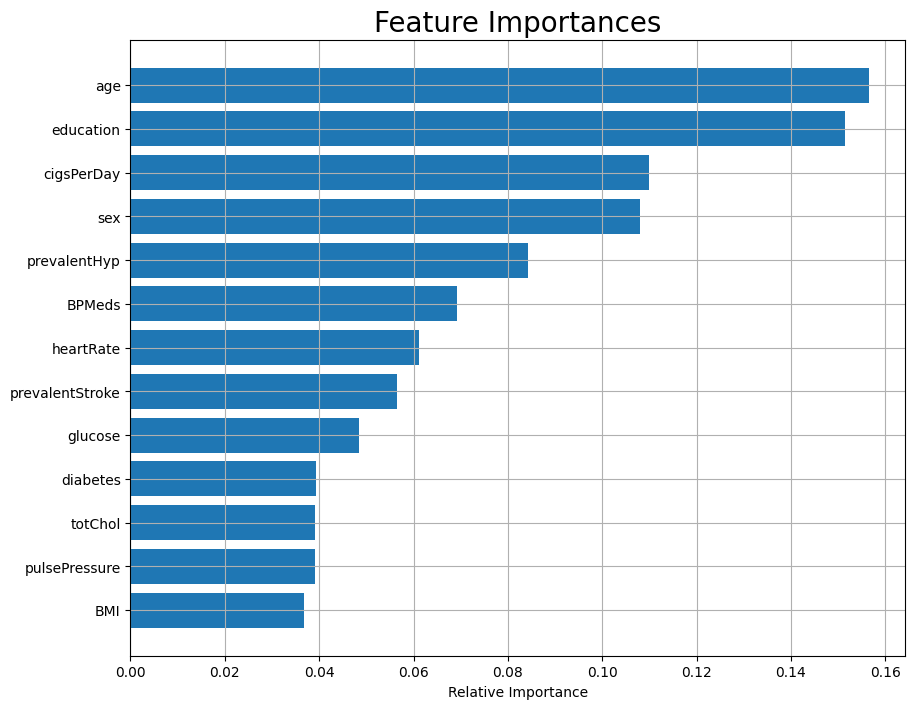

In [124]:
# Plotting the barplot to determine which feature is contributing the most
features = final_df.columns
importances = best_estimator.feature_importances_
indices = np.argsort(importances)
plt.figure(figsize=(10,8))
plt.grid(zorder=0)
plt.title('Feature Importances', fontsize=20)
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), features[indices])
plt.xlabel('Relative Importance')

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [125]:
# Importing pickle module
import pickle

In [126]:
# Save the File
filename='Cardiovascular_Risk_Prediction_Classification.pkl'

# serialize process (wb=write byte)
pickle.dump(best_estimator,open(filename,'wb'))

### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [127]:
# Load the File and predict unseen data.
Classification_model= pickle.load(open(filename,'rb'))

# Predicting the unseen data(test set)
Classification_model.predict(x_test)

array([1, 0, 0, ..., 0, 0, 1], shape=(1152,))

In [128]:
y_test_xgb_pred_gs

array([1, 0, 0, ..., 0, 0, 1], shape=(1152,))

### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

**Conclusion From EDA**

* vAge is a significant factor in determining CHD risk.

* Men are more likely to develop CHD than women.

* Smoking is a risk factor for CHD, and smoking intensity plays a role in determining the risk.

* Patients with high blood pressure, stroke, and diabetes are at higher risk for CHD.

* Patients who have had a prevalent stroke and prevalent hypertension are more likely to be at risk for CHD.

* Patients with diabetes are also more likely to be at risk for CHD.

* Total cholesterol levels are slightly higher in patients at risk for CHD.

* There is a positive relationship between certain variables such as age and systolic blood pressure, BMI and glucose levels.

**Conclusion From Model Implementation**

* Among the six models tested, the Random Forest Classifier and XGBoost models performed the best, with high accuracy, precision, and recall scores.

* While the KNN model had a relatively high recall score, its accuracy and precision scores were lower than those of the Random Forest Classifier and XGBoost models.

* The SVC model had a lower accuracy and ROC AUC score, indicating that it may not be as suitable for this particular classification problem.

* **The Random Forest Classifier model had slightly higher test accuracy** and precision scores than the XGBoost, and a higher ROC AUC score, suggesting that it may be a better choice for predicting cardiovascular risk.

* Based on the results presented, **the Random Forest Classifier** model was chosen as the best fit classification model for the cardiovascular risk prediction dataset **having accuracy of 90.36%.**

VOIS For Tech_AICTE_November Internship Batch_AI/ML